# 04 · Resultados y fichas de participación
La lectura comienza con un panorama general, continúa con los desgloses territoriales y
sociodemográficos y termina con las fichas técnicas. Estas salidas apoyan la caracterización
de los seis perfiles del Reto 1 del INE. Los nombres y la interpretación corresponden al equipo.

## Preparación
Carga de asignaciones y diagnósticos del notebook 03.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import matplotlib.colors as mcolors
import json
import re
from pathlib import Path
from textwrap import fill
from IPython.display import display
import utils as U

sns.set_theme(style="whitegrid")
# Rosa mexicano, maíz, azul Talavera, morado, verde y naranja.
PALETA_BASE = ["#E6007E", "#E5AD00", "#0066CC", "#812AA6", "#008F5A", "#F06400"]
PALETA = dict(enumerate(PALETA_BASE))
sns.set_palette(PALETA_BASE)
CMAP_COMPOSICION = mcolors.LinearSegmentedColormap.from_list(
    "composicion_mexicana", ["#FFF9ED", PALETA[4]])
CMAP_CONTRASTE = mcolors.LinearSegmentedColormap.from_list(
    "contraste_mexicano", [PALETA[2], "#FFF9ED", PALETA[0]])
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.3f}".format
u = pd.read_csv(U.DIR_PROC / "unidades_con_cluster.csv")
VARIABLES_MODELO_CONTINUAS = U.VARIABLES_PARTICIPACION
VARIABLES_DIAGNOSTICO = ["tendencia_general", "exceso_medio"]
VARIABLES_LONGITUDINALES = VARIABLES_MODELO_CONTINUAS + VARIABLES_DIAGNOSTICO
UNIDADES_VARIABLES = U.UNIDADES_INDICADORES
ETIQUETAS_VARIABLES = U.ETIQUETAS_INDICADORES
UMBRAL_BRECHA_ESTANDARIZADA_PP = 1.0
ANIOS = U.ANIOS
COLS_TASA = [f"tasa_{a}" for a in ANIOS]

requeridas = set(VARIABLES_LONGITUDINALES + COLS_TASA + [
    "cluster", "ln_media", "peso_clustering", "sexo", "grupo_edad", "distrito_ref",
    "id_distrito", "ciclo_vida", "region", "entidad", "silueta_individual",
    "features_set", "variables_clustering", "version_preprocesado", "version_variables",
    "nivel_territorial", "version_modelo", "algoritmo_clustering", "candidato_modelo",
    "criterio_seleccion"])
requeridas.update(f"{campo}_{a}" for campo in ["participantes", "denominador", "exceso"] for a in ANIOS)
faltan = requeridas - set(u.columns)
if faltan:
    raise ValueError(f"Faltan columnas en las asignaciones del 03: {sorted(faltan)}")
if u.empty:
    raise ValueError("La tabla de asignaciones no contiene segmentos.")
FEATURES_SET = str(u.features_set.iloc[0])
VARIABLES_CLUSTERING = u.variables_clustering.iloc[0].split(";")
if not u.features_set.eq("participacion").all() or not u.variables_clustering.eq(";".join(VARIABLES_MODELO_CONTINUAS)).all():
    raise ValueError("Las asignaciones no corresponden a las cuatro variables del modelo de participación.")
if (not u.version_preprocesado.eq("ccpc_edad114_especificados").all()
        or not u.version_variables.eq(U.VERSION_VARIABLES).all()
        or not u.version_modelo.eq(U.VERSION_MODELO).all()
        or not u.nivel_territorial.eq("distrito").all()):
    raise ValueError("Las versiones de las asignaciones no coinciden con el flujo actual de 02 y 03.")
if (not np.isfinite(u[VARIABLES_LONGITUDINALES + ["ln_media", "peso_clustering"]].to_numpy(float)).all()
        or u[["ln_media", "peso_clustering"]].le(0).any().any()):
    raise ValueError("Se requieren indicadores finitos y pesos positivos para calcular los resúmenes.")
PERFILES = sorted(u.cluster.unique().tolist())
K = len(PERFILES)
PESO = "ln_media"  # Composición de los perfiles.
PESO_VARIABLES = "peso_clustering"  # Mismo peso del ajuste del 03.
print(f"Base de resultados: {len(u):,} segmentos y {K} perfiles.")
CANDIDATO = str(u.candidato_modelo.iloc[0])
ALGORITMO = str(u.algoritmo_clustering.iloc[0])
CRITERIO = str(u.criterio_seleccion.iloc[0])
diagnostico_perfiles = pd.read_csv(U.ruta_set(U.DIR_TAB, "diagnostico_perfiles.csv", FEATURES_SET)).set_index("cluster").reindex(PERFILES)

asociaciones_factores = pd.read_csv(U.ruta_set(U.DIR_TAB, "asociaciones_factores.csv", FEATURES_SET))
u["peso_segmento"] = 1.

Base de resultados: 12,000 segmentos y 6 perfiles.


In [2]:
res = U.media_ponderada(u, VARIABLES_LONGITUDINALES, PESO_VARIABLES, "cluster").reindex(PERFILES)
res.insert(0, "n_segmentos", u.groupby("cluster").size())
res.insert(1, "%_ln_media", u.groupby("cluster")[PESO].sum() / u[PESO].sum() * 100)
referencia_variables = pd.Series({v: np.average(u[v], weights=u[PESO_VARIABLES]) for v in VARIABLES_LONGITUDINALES})
trayectorias = pd.DataFrame(index=pd.Index(PERFILES, name="cluster"))
trayectoria_base = pd.Series(index=COLS_TASA, dtype=float)
for a in ANIOS:
    agregados = u.groupby("cluster")[[f"participantes_{a}", f"denominador_{a}"]].sum()
    trayectorias[f"tasa_{a}"] = agregados[f"participantes_{a}"] / agregados[f"denominador_{a}"].where(agregados[f"denominador_{a}"] > 0)
    trayectoria_base[f"tasa_{a}"] = u[f"participantes_{a}"].sum() / u[f"denominador_{a}"].sum()
res = res.join(trayectorias)
campos_calidad = ["silueta_media", "silueta_mediana", "porcentaje_silueta_negativa",
                  "jaccard_media_entidad", "jaccard_p10_entidad", "repeticiones_validas_entidad"]
res = res.join(diagnostico_perfiles[campos_calidad])

trayectorias_estandarizadas, trayectorias_soporte_comun, cobertura_edades, pesos_edad, edades_comunes = U.estandarizar_trayectorias_edad(u, ANIOS)
trayectoria_base_estandarizada = pd.Series(index=COLS_TASA, dtype=float)
trayectoria_base_comun = pd.Series(index=COLS_TASA, dtype=float)
for a in ANIOS:
    t = u.groupby("grupo_edad", observed=True)[[f"participantes_{a}",f"denominador_{a}"]].sum()
    tasa_edad = t[f"participantes_{a}"]/t[f"denominador_{a}"]
    trayectoria_base_estandarizada[f"tasa_{a}"] = (tasa_edad.reindex(pesos_edad.index)*pesos_edad).sum()
    trayectoria_base_comun[f"tasa_{a}"] = ((tasa_edad.reindex(edades_comunes)*(
        pesos_edad[edades_comunes]/pesos_edad[edades_comunes].sum())).sum() if edades_comunes else np.nan)
if trayectorias_estandarizadas.notna().all().all():
    trayectorias_ficha = trayectorias_estandarizadas
    base_ficha = trayectoria_base_estandarizada
    titulo_estandar = "Estandarización por edad con soporte completo"
    masa_soporte = 1.
elif edades_comunes:
    trayectorias_ficha = trayectorias_soporte_comun
    base_ficha = trayectoria_base_comun
    masa_soporte = float(pesos_edad[edades_comunes].sum())
    titulo_estandar = f"Estandarización en soporte común ({masa_soporte:.1%} de LN media)"
else:
    trayectorias_ficha = trayectorias_estandarizadas
    base_ficha = trayectoria_base_estandarizada
    masa_soporte = 0.
    titulo_estandar = "Estandarización completa no identificable; no hay soporte común"
comparacion_brechas = pd.DataFrame({"anio":ANIOS,
    "brecha_cruda_pp":100*(trayectorias.max()-trayectorias.min()).to_numpy(),
    "brecha_estandarizada_pp":100*(trayectorias_ficha.max()-trayectorias_ficha.min()).to_numpy()})
comparacion_brechas["soporte_ln_media"] = masa_soporte
comparacion_brechas["menor_umbral_descriptivo"] = comparacion_brechas.brecha_estandarizada_pp.le(UMBRAL_BRECHA_ESTANDARIZADA_PP)


def composicion(var, peso=PESO):
    tabla = u.pivot_table(index="cluster", columns=var, values=peso, aggfunc="sum", fill_value=0).reindex(PERFILES)
    pct = tabla.div(tabla.sum(axis=1), axis=0) * 100
    base_pct = tabla.sum(axis=0) / tabla.to_numpy().sum() * 100
    return pct, pct.div(base_pct, axis=1) * 100

variables_composicion = ["ciclo_vida", "sexo", "region", "entidad"]
if "tipo_seccion" in u and u.tipo_seccion.nunique() > 1:
    variables_composicion.append("tipo_seccion")
comp = {v: composicion(v) for v in variables_composicion}
comp["ciclo_vida"] = tuple(t[[v for v in U.ORDEN_CICLO if v in t.columns]] for t in comp["ciclo_vida"])
comp_segmentos = {v:composicion(v,peso="peso_segmento") for v in variables_composicion}
diferencias_indices = []
for v in variables_composicion:
    indices_ln, indices_n = comp[v][1].align(comp_segmentos[v][1],join="outer",axis=None)
    diferencias = (indices_ln-indices_n).abs()
    for c in diferencias.index:
        for categoria in diferencias.columns:
            diferencias_indices.append({"variable":v,"cluster":c,"categoria":categoria,
                "indice_ln":indices_ln.loc[c,categoria],"indice_segmentos":indices_n.loc[c,categoria],
                "diferencia_absoluta":diferencias.loc[c,categoria]})
diferencias_indices = pd.DataFrame(diferencias_indices)


## 1. Resultados generales
Universo analizado, tamaño de los perfiles, participación en las seis elecciones y calidad del agrupamiento.

,Universo analizado
Segmentos incluidos,12000
Entidades representadas,32
Distritos de referencia,300
Grupos de edad,20
Categorías de sexo,2
Elecciones por segmento,6
Perfiles,6


,n_segmentos,%_ln_media,participacion_media,brecha_presidencial_intermedia,cambio_reciente,irregularidad_trayectoria
cluster,,,,,,
0,2261,22.515,41.640,14.570,0.078,2.999
1,1296,14.139,52.518,22.469,0.214,2.685
2,1222,11.720,54.666,10.606,-0.698,6.717
3,2368,20.010,58.200,5.672,-0.726,2.155
4,1807,13.534,59.610,16.292,1.340,5.306
5,3046,18.082,66.938,12.001,0.470,2.325


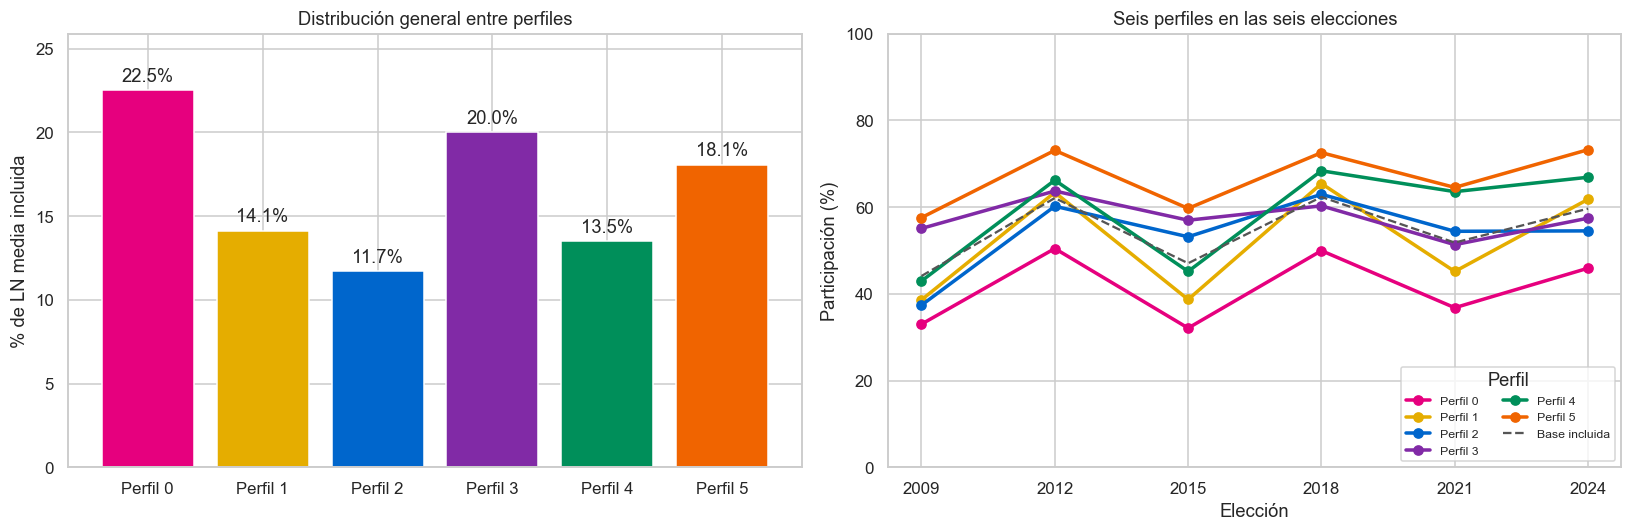

In [3]:
# Panorama del universo incluido y de la participación agregada.
panorama = pd.Series({
    "Segmentos incluidos": len(u),
    "Entidades representadas": u.entidad.nunique(),
    "Distritos de referencia": u.id_distrito.nunique(),
    "Grupos de edad": u.grupo_edad.nunique(),
    "Categorías de sexo": u.sexo.nunique(),
    "Elecciones por segmento": len(ANIOS),
    "Perfiles": K,
}, name="Universo analizado").to_frame()
display(panorama)
display(res[["n_segmentos", "%_ln_media"] + VARIABLES_MODELO_CONTINUAS].round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar([f"Perfil {c}" for c in PERFILES], res["%_ln_media"],
            color=[PALETA[c] for c in PERFILES])
axes[0].set(title="Distribución general entre perfiles", ylabel="% de LN media incluida")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=3)
axes[0].margins(y=.15)
for c in PERFILES:
    axes[1].plot(ANIOS, trayectorias.loc[c, COLS_TASA].to_numpy()*100,
                 "o-", color=PALETA[c], lw=2.3, label=f"Perfil {c}")
axes[1].plot(ANIOS, trayectoria_base.to_numpy()*100, "--", color="#555555",
             lw=1.5, label="Base incluida")
axes[1].set(title="Seis perfiles en las seis elecciones", xlabel="Elección",
            ylabel="Participación (%)", xticks=ANIOS, ylim=(0, 100))
axes[1].legend(title="Perfil", fontsize=8, ncol=2, loc="lower right")
fig.tight_layout()
fig.savefig(U.ruta_set(U.DIR_FIG, "resultados_generales.png", FEATURES_SET), dpi=200, bbox_inches="tight")
plt.show(); plt.close()


Silueta exacta de participación: 0.238


,selección
modelo,km_participacion
algoritmo,kmeans
criterio,"Seis perfiles de participación; nivel, brecha,..."


,n_segmentos,silueta_media,silueta_mediana,silueta_p10,porcentaje_silueta_negativa,silueta_media_referencia,jaccard_media_entidad,jaccard_p10_entidad,repeticiones_validas_entidad,sd_intra_participacion_media,eta2_entre_perfiles_participacion_media,sd_intra_brecha_presidencial_intermedia,eta2_entre_perfiles_brecha_presidencial_intermedia,sd_intra_tendencia_general,eta2_entre_perfiles_tendencia_general,sd_intra_diferencia_tendencias,eta2_entre_perfiles_diferencia_tendencias,sd_intra_curvatura_intermedia,eta2_entre_perfiles_curvatura_intermedia,sd_intra_curvatura_presidencial,eta2_entre_perfiles_curvatura_presidencial
cluster,,,,,,,,,,,,,,,,,,,,,
0,2261,0.209,0.205,0.045,2.256,0.209,0.704,0.378,20,6.654,0.522,3.448,0.662,0.504,0.447,0.568,0.537,9.401,0.424,8.919,0.212
1,1296,0.243,0.240,0.062,0.000,0.243,0.690,0.380,20,7.455,0.522,3.297,0.662,0.379,0.447,0.477,0.537,7.750,0.424,5.160,0.212
2,1222,0.228,0.234,-0.000,10.147,0.228,0.897,0.850,20,10.921,0.522,3.445,0.662,0.527,0.447,0.709,0.537,19.634,0.424,7.615,0.212
3,2368,0.255,0.263,0.047,2.407,0.255,0.762,0.476,20,9.694,0.522,3.509,0.662,0.412,0.447,0.385,0.537,7.199,0.424,6.882,0.212
4,1807,0.231,0.243,0.033,5.645,0.231,0.884,0.818,20,8.504,0.522,3.302,0.662,0.473,0.447,0.588,0.537,9.947,0.424,8.056,0.212
5,3046,0.253,0.260,0.063,0.919,0.253,0.831,0.686,20,6.524,0.522,3.475,0.662,0.444,0.447,0.457,0.537,8.763,0.424,6.256,0.212


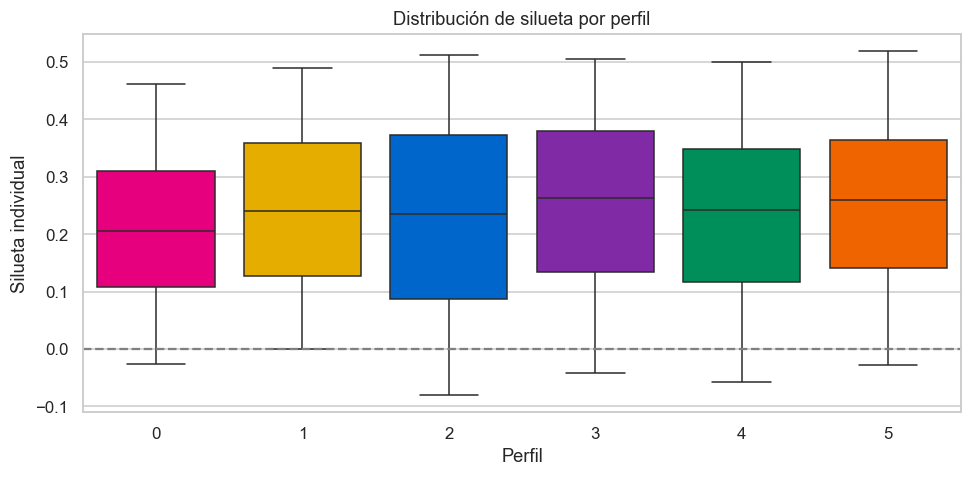

In [4]:
display(pd.Series({"modelo": CANDIDATO, "algoritmo": ALGORITMO, "criterio": CRITERIO}, name="selección").to_frame())
print(f"Silueta exacta de participación: {u.silueta_individual.mean():.3f}")
display(diagnostico_perfiles)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=u, x="cluster", y="silueta_individual", hue="cluster", palette=PALETA, dodge=False, legend=False, saturation=1, showfliers=False, ax=ax)
ax.axhline(0, color="gray", ls="--")
ax.set(title="Distribución de silueta por perfil", xlabel="Perfil", ylabel="Silueta individual")
plt.tight_layout(); plt.savefig(U.ruta_set(U.DIR_FIG, "silueta_por_perfil.png", FEATURES_SET), dpi=180, bbox_inches="tight"); plt.show(); plt.close()


## 2. Resultados desglosados

### 2.1. Territorio
Los mapas muestran qué porcentaje de la LN media incluida de cada estado corresponde a cada perfil.
Las tablas regionales muestran de dónde procede la LN media del perfil. La asignación distrital es aproximada.

presencia_perfil_0  ...  presencia_perfil_5
entidad             distrito_ref                      ...                    
AGUASCALIENTES      1                         23.665  ...               4.388
                    2                         58.597  ...              20.351
                    3                         30.860  ...              18.295
BAJA CALIFORNIA     1                         63.848  ...              17.007
                    2                         80.139  ...              11.682
                    3                         49.334  ...              12.546
                    4                         82.980  ...               0.000
                    5                         77.986  ...               9.802
                    6                         96.124  ...               3.876
                    7                         80.711  ...              16.410
                    8                         85.800  ...               4.855
                    9                        100.000  ...               0.000
BAJA CALIFORNIA SUR 1                          5.604  ...               5.206
                    2                         65.673  ...              10.346
CAMPECHE            1                          1.333  ...              15.486
                    2                          1.970  ...               5.964
CHIAPAS             1                          0.000  ...               0.000
                    2                          0.000  ...               0.716
                    3                          0.711  ...               0.000
                    4                          0.000  ...               0.000

[20 rows x 6 columns]

,presencia_perfil_0,presencia_perfil_1,presencia_perfil_2,presencia_perfil_3,presencia_perfil_4,presencia_perfil_5
entidad_fuente,,,,,,
AGUASCALIENTES,36.883,14.663,0.000,0.000,34.040,14.415
BAJA CALIFORNIA,79.740,10.320,0.000,0.272,1.284,8.384
BAJA CALIFORNIA SUR,29.414,0.000,62.629,0.714,0.000,7.243
CAMPECHE,1.650,0.000,0.000,87.607,0.000,10.743
CHIAPAS,11.102,8.010,22.923,0.000,56.511,1.454
CHIHUAHUA,54.856,1.942,0.000,0.000,37.984,5.218
CIUDAD DE MEXICO,0.858,72.797,0.000,0.000,5.812,20.533
COAHUILA,28.638,0.906,0.000,0.390,34.155,35.911
COLIMA,0.000,0.000,0.000,99.504,0.000,0.496


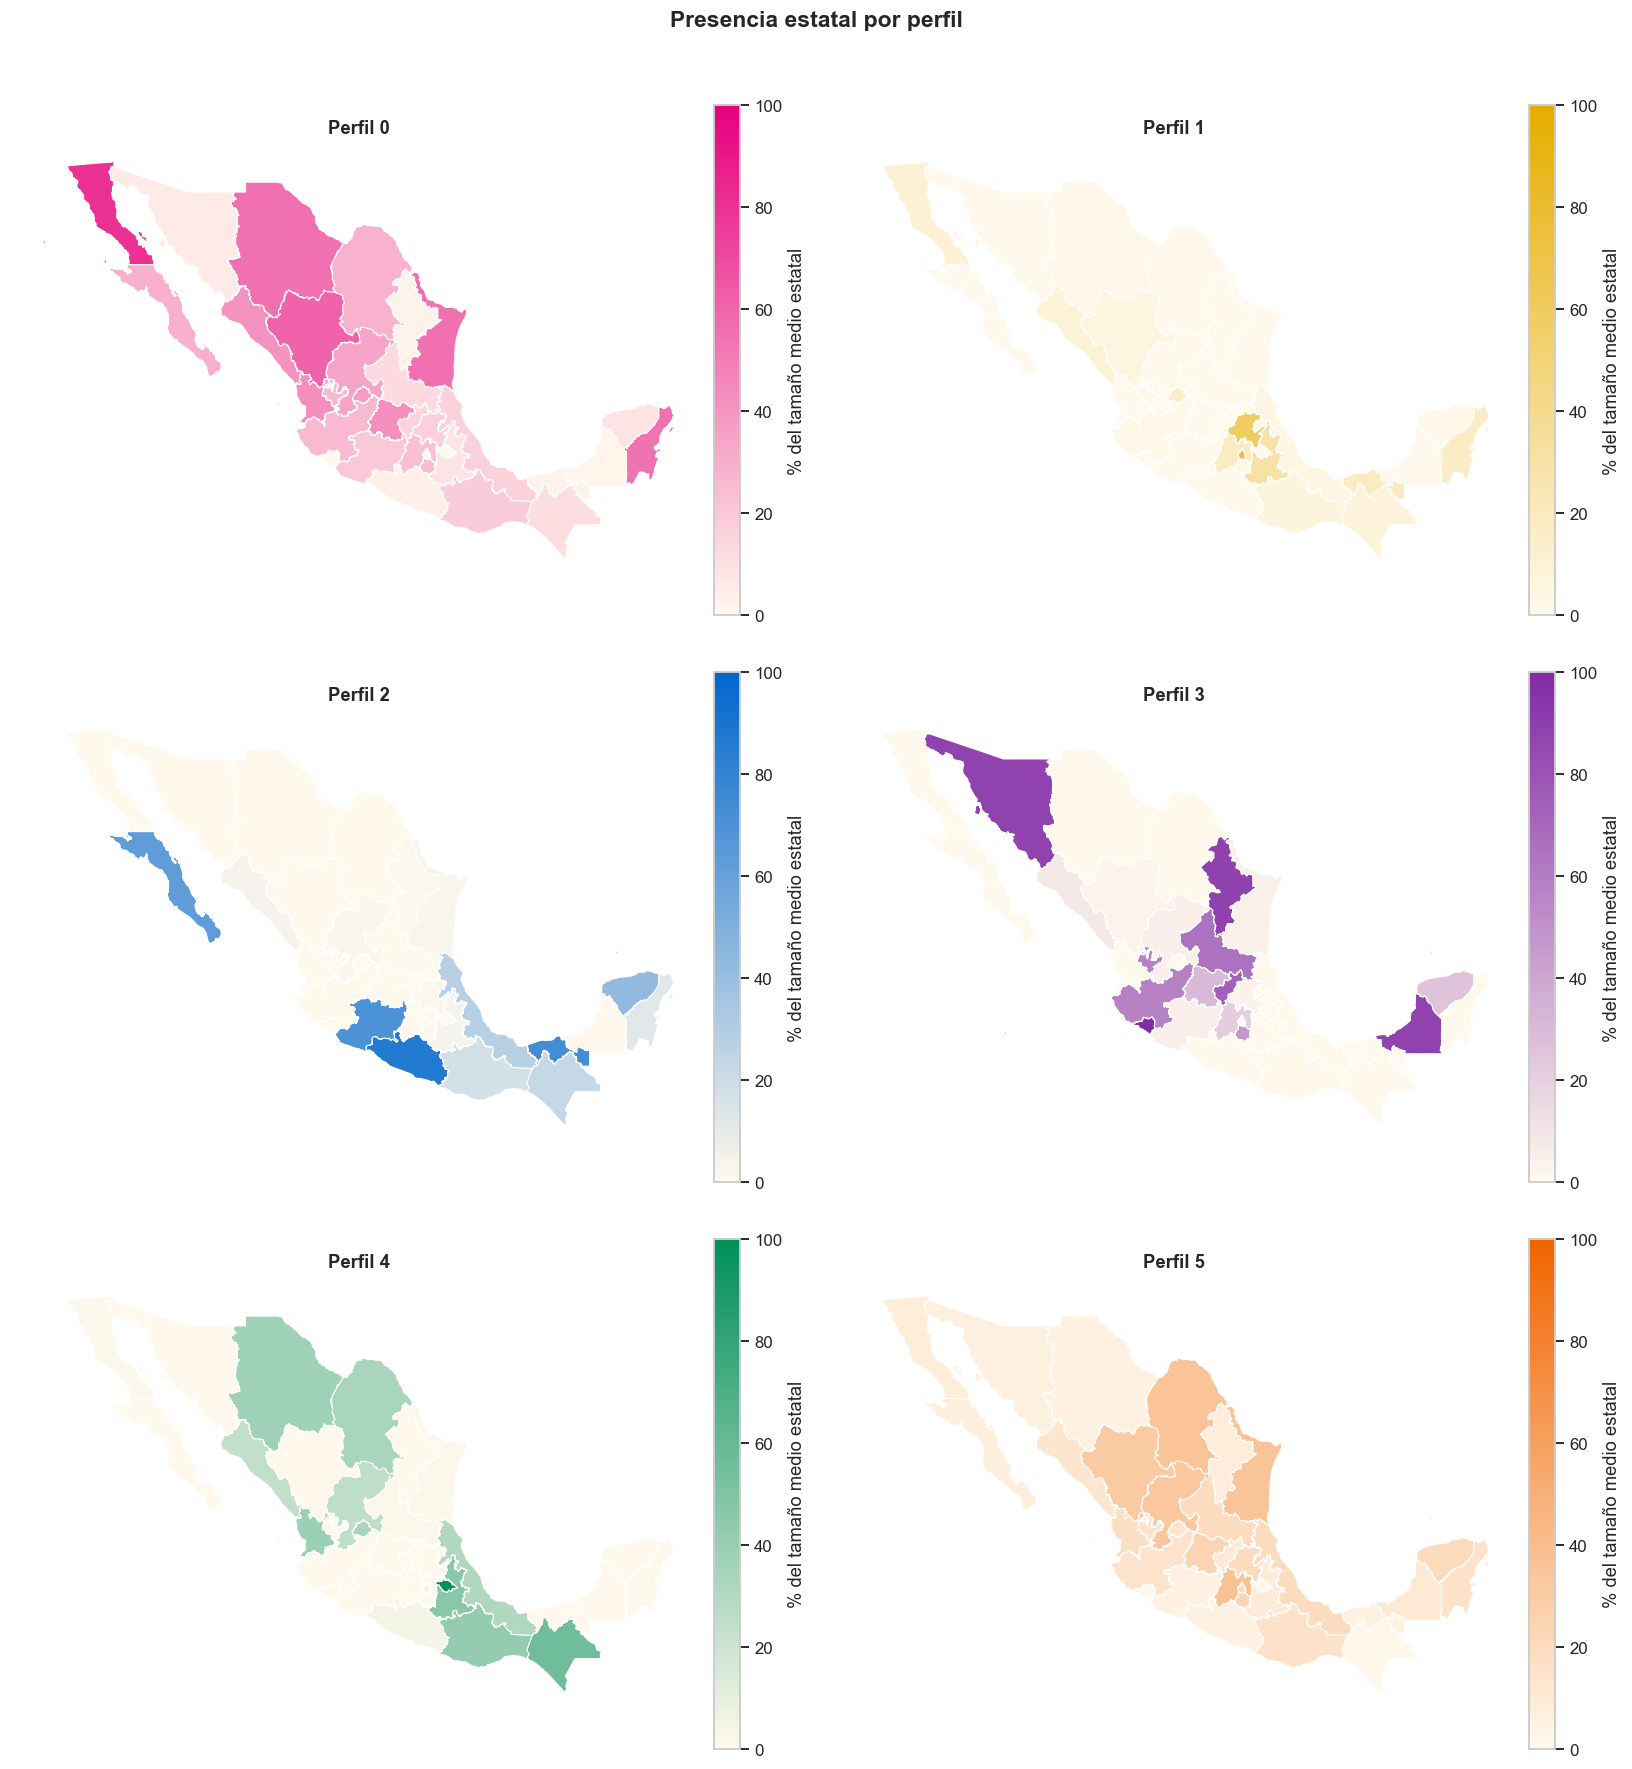

In [5]:
presencia_distrito = u.pivot_table(index=["entidad", "distrito_ref"], columns="cluster",
    values=PESO, aggfunc="sum", fill_value=0).reindex(columns=PERFILES, fill_value=0)
presencia_distrito = presencia_distrito.div(presencia_distrito.sum(axis=1), axis=0)*100
presencia_distrito.columns = [f"presencia_perfil_{c}" for c in presencia_distrito.columns]
display(presencia_distrito.head(20))

def _normalizar_texto(valor):
    if pd.isna(valor):
        return pd.NA
    texto = str(valor).strip().upper()
    reemplazos = str.maketrans({
        "Á": "A", "É": "E", "Í": "I", "Ó": "O", "Ú": "U", "Ü": "U", "Ñ": "N"
    })
    texto = texto.translate(reemplazos)
    texto = re.sub(r"[^A-Z0-9 ]+", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

ALIASES_ENTIDAD = {
    "COAHUILA": "COAHUILA DE ZARAGOZA",
    "MICHOACAN": "MICHOACAN DE OCAMPO",
    "VERACRUZ": "VERACRUZ DE IGNACIO DE LA LLAVE",
    "MEXICO": "MEXICO",
    "ESTADO DE MEXICO": "MEXICO",
    "CDMX": "CIUDAD DE MEXICO",
    "DISTRITO FEDERAL": "CIUDAD DE MEXICO"
}

def _normalizar_entidad(valor):
    texto = _normalizar_texto(valor)
    if pd.isna(texto):
        return pd.NA
    return ALIASES_ENTIDAD.get(texto, texto)


def cargar_mapa_entidades(cache_path=None):
    cache_path = Path(U.DIR_PROC) / "mexico_entidades.geojson" if cache_path is None else Path(cache_path)
    url = "https://gaia.inegi.org.mx/wscatgeo/v2/geo/mgee/"
    if cache_path.exists():
        try:
            return gpd.read_file(cache_path)
        except Exception:
            pass
    try:
        import requests
        respuesta = requests.get(url, timeout=60)
        respuesta.raise_for_status()
        data = respuesta.json()
        cache_path.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
        return gpd.GeoDataFrame.from_features(data["features"], crs="EPSG:4326")
    except Exception as e:
        if cache_path.exists():
            return gpd.read_file(cache_path)
        raise RuntimeError("No fue posible descargar ni leer la cartografía de entidades.") from e


def preparar_mapa_entidades(gdf):
    gdf = gdf.copy()
    col_nombre = next((c for c in gdf.columns if c.lower() in {"nomgeo", "nom_ent", "nombre", "name"}), None)
    col_clave = next((c for c in gdf.columns if c.lower() in {"cvegeo", "cve_ent", "cvegeoedo", "id"}), None)
    if col_nombre is None:
        raise ValueError("No se identificó la columna con el nombre de la entidad en la cartografía.")
    gdf["entidad_nombre_mapa"] = gdf[col_nombre]
    gdf["entidad_norm"] = gdf[col_nombre].map(_normalizar_entidad)
    if col_clave is not None:
        gdf["entidad_cve"] = gdf[col_clave].astype(str).str.extract(r"(\d{2})")[0]
    else:
        gdf["entidad_cve"] = pd.NA
    return gdf

presencia_entidad = (
    u.pivot_table(index="entidad", columns="cluster", values=PESO, aggfunc="sum", fill_value=0)
     .reindex(columns=PERFILES)
)
presencia_entidad = presencia_entidad.div(presencia_entidad.sum(axis=1), axis=0) * 100
presencia_entidad.columns = [f"presencia_perfil_{c}" for c in presencia_entidad.columns]
presencia_entidad = presencia_entidad.reset_index().rename(columns={"entidad": "entidad_fuente"})
presencia_entidad["entidad_norm"] = presencia_entidad["entidad_fuente"].map(_normalizar_entidad)
presencia_entidad["entidad_cve"] = pd.to_numeric(presencia_entidad["entidad_fuente"], errors="coerce").astype("Int64").astype(str)
presencia_entidad["entidad_cve"] = presencia_entidad["entidad_cve"].replace("<NA>", pd.NA).str.zfill(2)

columnas_presencia = [c for c in presencia_entidad.columns if c.startswith("presencia_perfil_")]
mapa_entidades = preparar_mapa_entidades(cargar_mapa_entidades())
base_por_codigo = presencia_entidad.dropna(subset=["entidad_cve"]).drop_duplicates(subset=["entidad_cve"])
base_por_nombre = presencia_entidad.dropna(subset=["entidad_norm"]).drop_duplicates(subset=["entidad_norm"])

mapa_perfiles = mapa_entidades.merge(base_por_codigo[["entidad_cve"] + columnas_presencia], on="entidad_cve", how="left")
mapa_perfiles = mapa_perfiles.merge(base_por_nombre[["entidad_norm"] + columnas_presencia], on="entidad_norm", how="left", suffixes=("", "_nom"))
for col in columnas_presencia:
    col_nom = f"{col}_nom"
    if col_nom in mapa_perfiles.columns:
        mapa_perfiles[col] = mapa_perfiles[col].fillna(mapa_perfiles[col_nom])

mapa_perfiles = mapa_perfiles[[c for c in mapa_perfiles.columns if not c.endswith("_nom")]].copy()
display(presencia_entidad.set_index("entidad_fuente")[columnas_presencia].sort_index())

perfiles_mapa = PERFILES  # Los seis perfiles, en dos columnas.
max_observado = np.nanmax(mapa_perfiles[[f"presencia_perfil_{c}" for c in perfiles_mapa]].to_numpy())
max_observado = float(max_observado) if np.isfinite(max_observado) else 0.
vmax_mapa = max(5., np.ceil(max_observado / 5.) * 5.) if max_observado > 0 else 100.

n_columnas = 2
n_filas = (len(perfiles_mapa) + 1) // 2
fig, axes = plt.subplots(n_filas, n_columnas, figsize=(15, 5.5*n_filas))
axes = axes.ravel()
for ax, c in zip(axes, perfiles_mapa):
    col = f"presencia_perfil_{c}"
    cmap = mcolors.LinearSegmentedColormap.from_list(f"perfil_{c}", ["#FFF9ED", PALETA[c]])
    mapa_perfiles.plot(
        column=col, cmap=cmap, linewidth=.7, edgecolor="white", ax=ax,
        vmin=0, vmax=vmax_mapa, legend=False,
        missing_kwds={"color": "#E6E6E6", "edgecolor": "white", "hatch": "///", "label": "Sin datos"}
    )
    ax.set_title(f"Perfil {c}", fontsize=12, fontweight="bold")
    ax.axis("off")
    sm = plt.cm.ScalarMappable(norm=plt.Normalize(vmin=0, vmax=vmax_mapa), cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.035, pad=0.01)
    cbar.set_label("% del tamaño medio estatal")

for ax in axes[len(perfiles_mapa):]:
    ax.set_axis_off()

fig.suptitle("Presencia estatal por perfil", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, .97))
plt.savefig(U.ruta_set(U.DIR_FIG, "mapas_presencia_estatal_perfiles.png", FEATURES_SET), dpi=220, bbox_inches="tight")
plt.show(); plt.close()

for c in perfiles_mapa:
    fig_i, ax_i = plt.subplots(1, 1, figsize=(8, 7))
    col = f"presencia_perfil_{c}"
    cmap = mcolors.LinearSegmentedColormap.from_list(f"perfil_individual_{c}", ["#FFF9ED", PALETA[c]])
    mapa_perfiles.plot(
        column=col, cmap=cmap, linewidth=.8, edgecolor="white", ax=ax_i,
        vmin=0, vmax=vmax_mapa,
        missing_kwds={"color": "#E6E6E6", "edgecolor": "white", "hatch": "///"},
        legend=True, legend_kwds={"label": "% del tamaño medio estatal", "shrink": .7}
    )
    ax_i.set_title(f"Perfil {c} — presencia estatal", fontsize=14, fontweight="bold")
    ax_i.axis("off")
    fig_i.tight_layout()
    plt.savefig(U.ruta_set(U.DIR_FIG, f"mapa_presencia_estatal_perfil_{c}.png", FEATURES_SET), dpi=220, bbox_inches="tight")
    plt.close(fig_i)


In [6]:
display(comp["region"][0].round(2))
display(comp["entidad"][0].round(2))


region,Circ. 1,Circ. 2,Circ. 3,Circ. 4,Circ. 5
cluster,,,,,
0,37.180,25.140,13.370,6.340,17.970
1,5.700,1.350,10.180,65.920,16.840
2,3.880,1.570,47.400,23.320,23.830
3,30.630,35.160,5.550,4.250,24.410
4,16.100,12.240,41.700,29.580,0.380
5,13.820,24.840,14.320,17.970,29.050


entidad,AGUASCALIENTES,BAJA CALIFORNIA,BAJA CALIFORNIA SUR,CAMPECHE,CHIAPAS,CHIHUAHUA,CIUDAD DE MEXICO,COAHUILA,COLIMA,DURANGO,GUANAJUATO,GUERRERO,HIDALGO,JALISCO,MEXICO,MICHOACAN,MORELOS,NAYARIT,NUEVO LEON,OAXACA,PUEBLA,QUERETARO,QUINTANA ROO,SAN LUIS POTOSI,SINALOA,SONORA,TABASCO,TAMAULIPAS,TLAXCALA,VERACRUZ,YUCATAN,ZACATECAS
cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1.730,10.710,0.750,0.050,1.940,7.560,0.330,3.060,0.000,3.900,9.290,0.470,1.740,7.540,13.450,3.340,1.740,1.810,0.500,2.620,2.060,1.180,3.130,1.250,4.330,0.580,0.200,7.270,0.000,4.750,0.670,2.030
1,1.100,2.210,0.000,0.000,2.230,0.430,44.860,0.150,0.000,0.560,0.000,0.000,9.730,0.830,16.840,0.000,0.320,0.000,0.000,1.500,11.020,0.000,1.560,0.000,1.680,0.000,2.420,0.100,0.000,2.230,0.230,0.000
2,0.000,0.000,3.060,0.000,7.700,0.000,0.000,0.000,0.000,0.000,0.220,20.820,0.370,0.000,0.590,23.240,0.270,0.000,0.320,4.780,1.860,0.000,1.340,0.090,0.820,0.000,11.840,0.720,0.000,15.470,6.270,0.230
3,0.000,0.040,0.020,3.120,0.000,0.000,0.000,0.050,2.930,0.170,7.560,0.000,0.400,19.130,14.090,1.000,3.850,0.000,19.290,0.000,0.000,6.400,0.000,7.270,0.960,10.300,0.040,0.650,0.000,0.140,2.260,0.350
4,2.660,0.290,0.000,0.000,16.440,8.710,3.740,6.080,0.000,0.000,0.370,0.940,0.030,0.030,0.380,0.000,0.000,2.710,0.000,10.160,17.210,0.000,0.130,0.270,4.320,0.050,0.000,0.390,7.670,14.980,0.000,2.470
5,0.840,1.400,0.230,0.420,0.320,0.900,9.890,4.780,0.020,2.500,6.600,0.850,2.640,5.410,26.830,1.170,2.160,0.950,1.880,2.780,2.430,1.040,1.120,2.440,1.680,0.760,0.570,5.830,0.000,7.090,2.020,2.450


### 2.2. Edad
Distribución de cada grupo de edad entre perfiles y composición por etapa de vida.
Se comparan las proporciones de LN media y de segmentos.

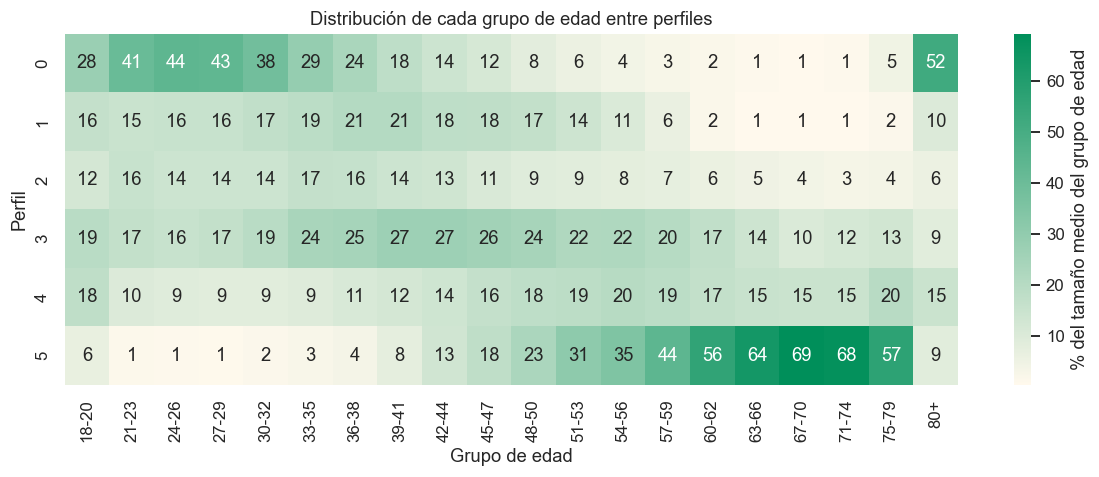

ciclo_vida,Adultos (30-50),Jóvenes (18-29),Mayores (67+),Mediana edad (51-66)
cluster,,,,
0,855,939,368,99
1,699,358,61,178
2,589,331,90,212
3,1081,429,251,607
4,570,281,389,567
5,406,62,1241,1337


ciclo_vida,Adultos (30-50),Jóvenes (18-29),Mayores (67+),Mediana edad (51-66)
cluster,,,,
0,-5.460,-3.969,-4.982,-13.725
1,-2.283,0.558,1.978,-2.459
2,2.714,2.125,-1.213,-0.128
3,3.161,4.230,-2.192,0.343
4,2.436,2.533,-1.016,-0.342
5,3.018,8.453,1.650,1.380


grupo_edad         18-20  21-23  24-26  27-29  ...  67-70  71-74  75-79    80+
peso      cluster                              ...                            
LN media  0       27.841 40.859 43.786 43.471  ...  0.634  1.115  4.641 51.951
          1       16.357 15.063 15.729 15.793  ...  0.515  0.625  1.769  9.929
          2       12.161 15.676 14.300 14.224  ...  4.169  3.352  3.778  5.793
          3       19.315 16.817 15.779 16.853  ... 10.453 12.007 13.023  8.742
          4       17.879 10.175  9.155  8.633  ... 14.983 14.849 19.712 14.860
          5        6.447  1.411  1.252  1.027  ... 69.246 68.052 57.077  8.725
Segmentos 0       27.500 41.167 44.167 43.667  ...  0.833  1.667  5.333 53.500
          1       15.667 14.500 14.833 14.667  ...  0.500  0.667  1.833  7.167
          2       12.167 15.000 13.833 14.167  ...  3.667  3.167  3.500  4.667
          3       19.833 17.500 16.500 17.667  ... 10.667 11.500 12.000  7.667
          4       18.333 10.333  9.333  8.833  ... 15.833 15.000 19.167 14.833
          5        6.500  1.500  1.333  1.000  ... 68.500 68.000 58.167 12.167

[12 rows x 20 columns]

ciclo_vida,Jóvenes (18-29),Adultos (30-50),Mediana edad (51-66),Mayores (67+)
cluster,,,,
0,49.900,40.650,2.870,6.580
1,31.600,56.280,9.850,2.280
2,34.410,50.300,11.660,3.630
3,24.300,51.800,18.540,5.370
4,23.470,39.400,25.540,11.580
5,3.700,21.640,47.160,27.500


In [7]:
orden_edad = U.orden_grupos_edad(u["grupo_edad"])
t = u.pivot_table(index="cluster", columns="grupo_edad", values=PESO, aggfunc="sum", fill_value=0).reindex(PERFILES)[orden_edad]
dist_edad = t.div(t.sum(axis=0), axis=1) * 100
plt.figure(figsize=(max(11, len(orden_edad) * .42), 4.5))
sns.heatmap(dist_edad, annot=True, fmt=".0f", cmap=CMAP_COMPOSICION, cbar_kws={"label": "% del tamaño medio del grupo de edad"})
plt.title("Distribución de cada grupo de edad entre perfiles")
plt.ylabel("Perfil"); plt.xlabel("Grupo de edad")
plt.tight_layout(); plt.savefig(U.ruta_set(U.DIR_FIG, "edad_vs_perfil.png", FEATURES_SET), dpi=200, bbox_inches="tight"); plt.show(); plt.close()
t_segmentos = u.pivot_table(index="cluster",columns="grupo_edad",values="peso_segmento",
    aggfunc="sum",fill_value=0).reindex(PERFILES)[orden_edad]
dist_edad_segmentos = t_segmentos.div(t_segmentos.sum(axis=0),axis=1)*100
valor_ciclo = "exceso_medio"
matriz_perfil_ciclo = u.groupby(["cluster","ciclo_vida"],observed=True).agg(
    n_segmentos=("cluster","size"),valor_medio=(valor_ciclo,"mean")).reset_index()
matriz_perfil_ciclo["variable_resumida"] = valor_ciclo
display(matriz_perfil_ciclo.pivot(index="cluster",columns="ciclo_vida",values="n_segmentos"))
display(matriz_perfil_ciclo.pivot(index="cluster",columns="ciclo_vida",values="valor_medio"))

display(pd.concat({"LN media":dist_edad,"Segmentos":dist_edad_segmentos},names=["peso","cluster"]))

display(comp["ciclo_vida"][0].round(2))


### 2.3. Sexo
Composición de cada perfil según las categorías presentes en la base elegible.

sexo               Hombres  Mujeres
peso      cluster                  
LN media  0         67.970   32.030
          1         38.090   61.910
          2         49.570   50.430
          3         48.620   51.380
          4         36.500   63.500
          5         38.540   61.460
Segmentos 0         65.100   34.900
          1         40.430   59.570
          2         50.160   49.840
          3         51.220   48.780
          4         41.890   58.110
          5         46.650   53.350

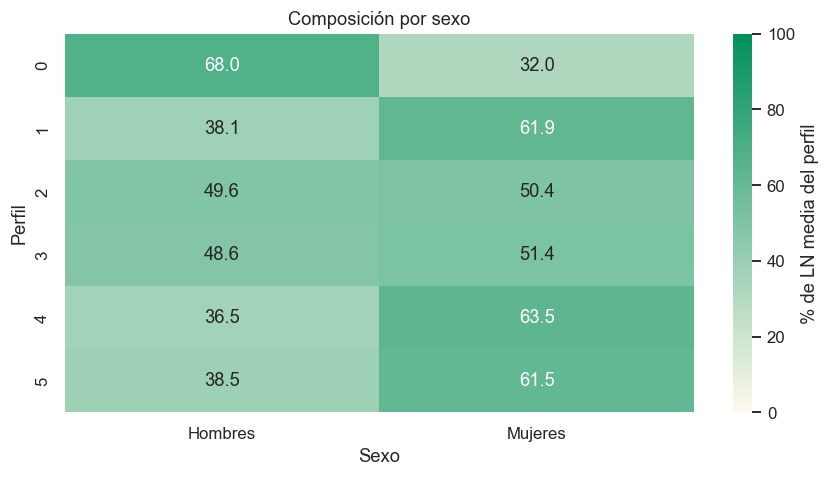

In [8]:
display(pd.concat({"LN media": comp["sexo"][0], "Segmentos": comp_segmentos["sexo"][0]}, names=["peso", "cluster"]).round(2))
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(comp["sexo"][0], annot=True, fmt=".1f", cmap=CMAP_COMPOSICION, vmin=0, vmax=100,
            ax=ax, cbar_kws={"label": "% de LN media del perfil"})
ax.set(title="Composición por sexo", xlabel="Sexo", ylabel="Perfil")
plt.tight_layout(); plt.savefig(U.ruta_set(U.DIR_FIG, "composicion_sexo.png", FEATURES_SET), dpi=180, bbox_inches="tight"); plt.show(); plt.close()


### 2.4. Participación
Trayectorias, indicadores y variación dentro de cada perfil. Las curvas agregan participantes y
denominadores; los promedios de indicadores utilizan los pesos del modelo.

In [9]:

display(pd.Series({v: UNIDADES_VARIABLES[v] for v in VARIABLES_LONGITUDINALES}, name="unidad").to_frame())
display(asociaciones_factores)
display(cobertura_edades)
display(comparacion_brechas)


,unidad
participacion_media,%
brecha_presidencial_intermedia,pp
cambio_reciente,pp/año
irregularidad_trayectoria,pp
tendencia_general,pp/año
exceso_medio,pp


,factor,peso,ari,nmi,cramer_v
0,grupo_edad,segmentos,0.045,0.107,0.307
1,ciclo_vida,segmentos,0.082,0.112,0.323
2,region,segmentos,0.088,0.142,0.341
3,entidad,segmentos,0.101,0.269,0.565
4,sexo,segmentos,0.009,0.011,0.162
5,grupo_edad,ln_media,NaN,0.094,0.294
6,ciclo_vida,ln_media,NaN,0.102,0.319
7,region,ln_media,NaN,0.152,0.352
8,entidad,ln_media,NaN,0.288,0.580
9,sexo,ln_media,NaN,0.023,0.235


,cluster,anio,peso_edad_cubierto,edades_ausentes,cobertura_completa
0,0,2009,1.000,,True
1,1,2009,1.000,,True
2,2,2009,1.000,,True
3,3,2009,1.000,,True
4,4,2009,1.000,,True
5,5,2009,1.000,,True
6,0,2012,1.000,,True
7,1,2012,1.000,,True
8,2,2012,1.000,,True
9,3,2012,1.000,,True


,anio,brecha_cruda_pp,brecha_estandarizada_pp,soporte_ln_media,menor_umbral_descriptivo
0,2009,24.564,20.791,1.000,False
1,2012,22.642,16.699,1.000,False
2,2015,27.596,21.583,1.000,False
3,2018,22.605,17.327,1.000,False
4,2021,27.741,22.045,1.000,False
5,2024,27.328,19.072,1.000,False


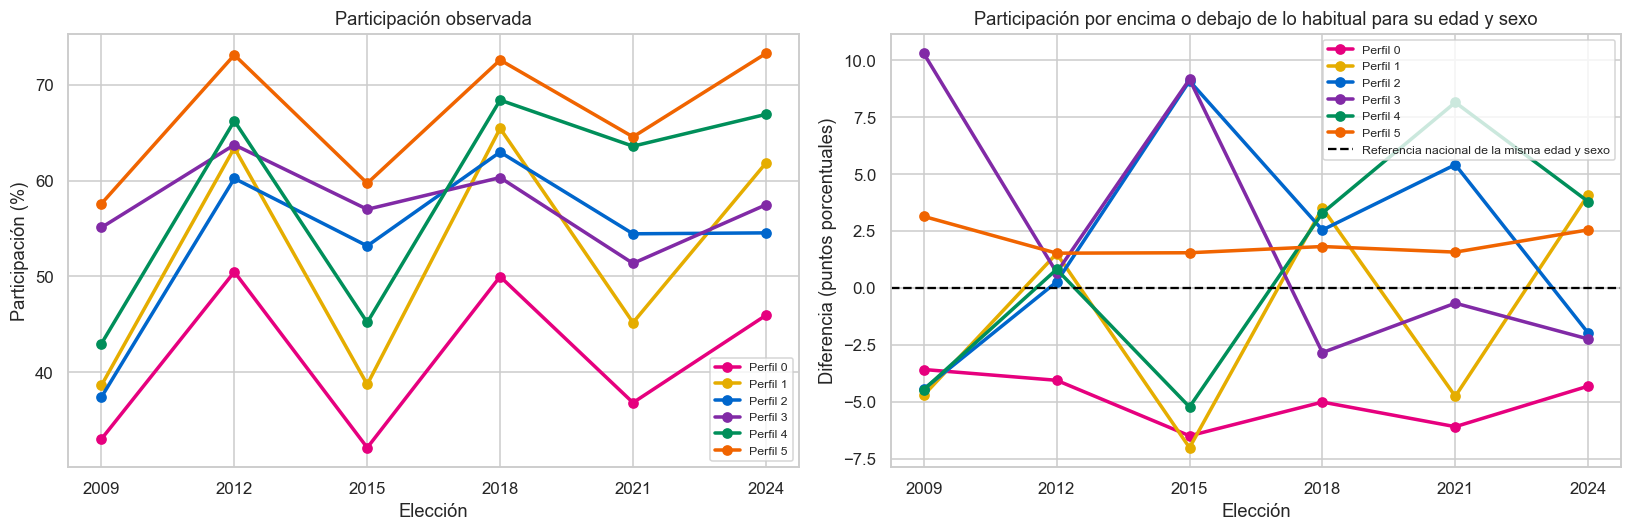

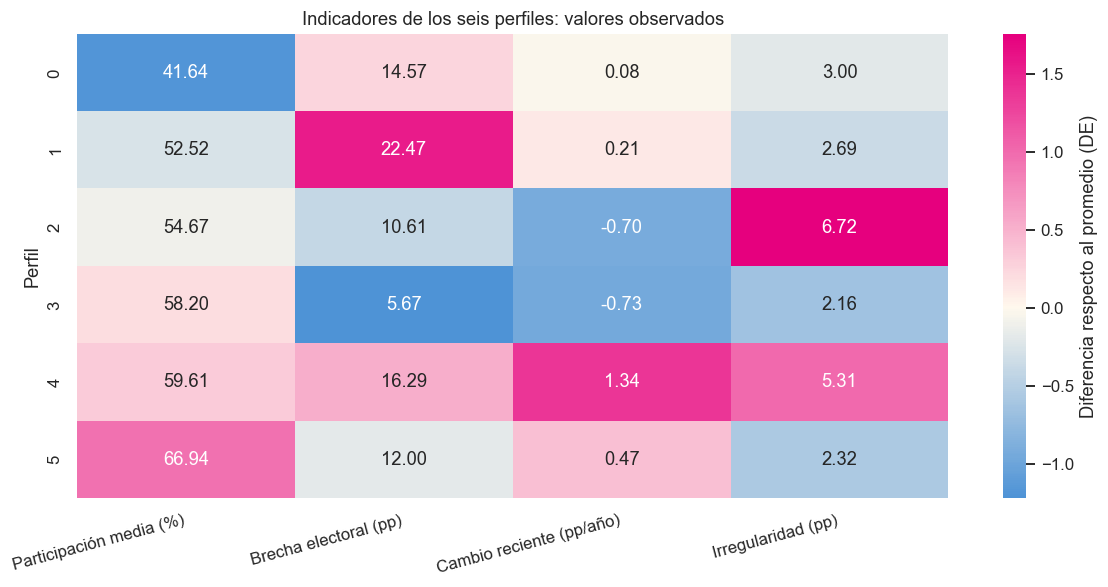

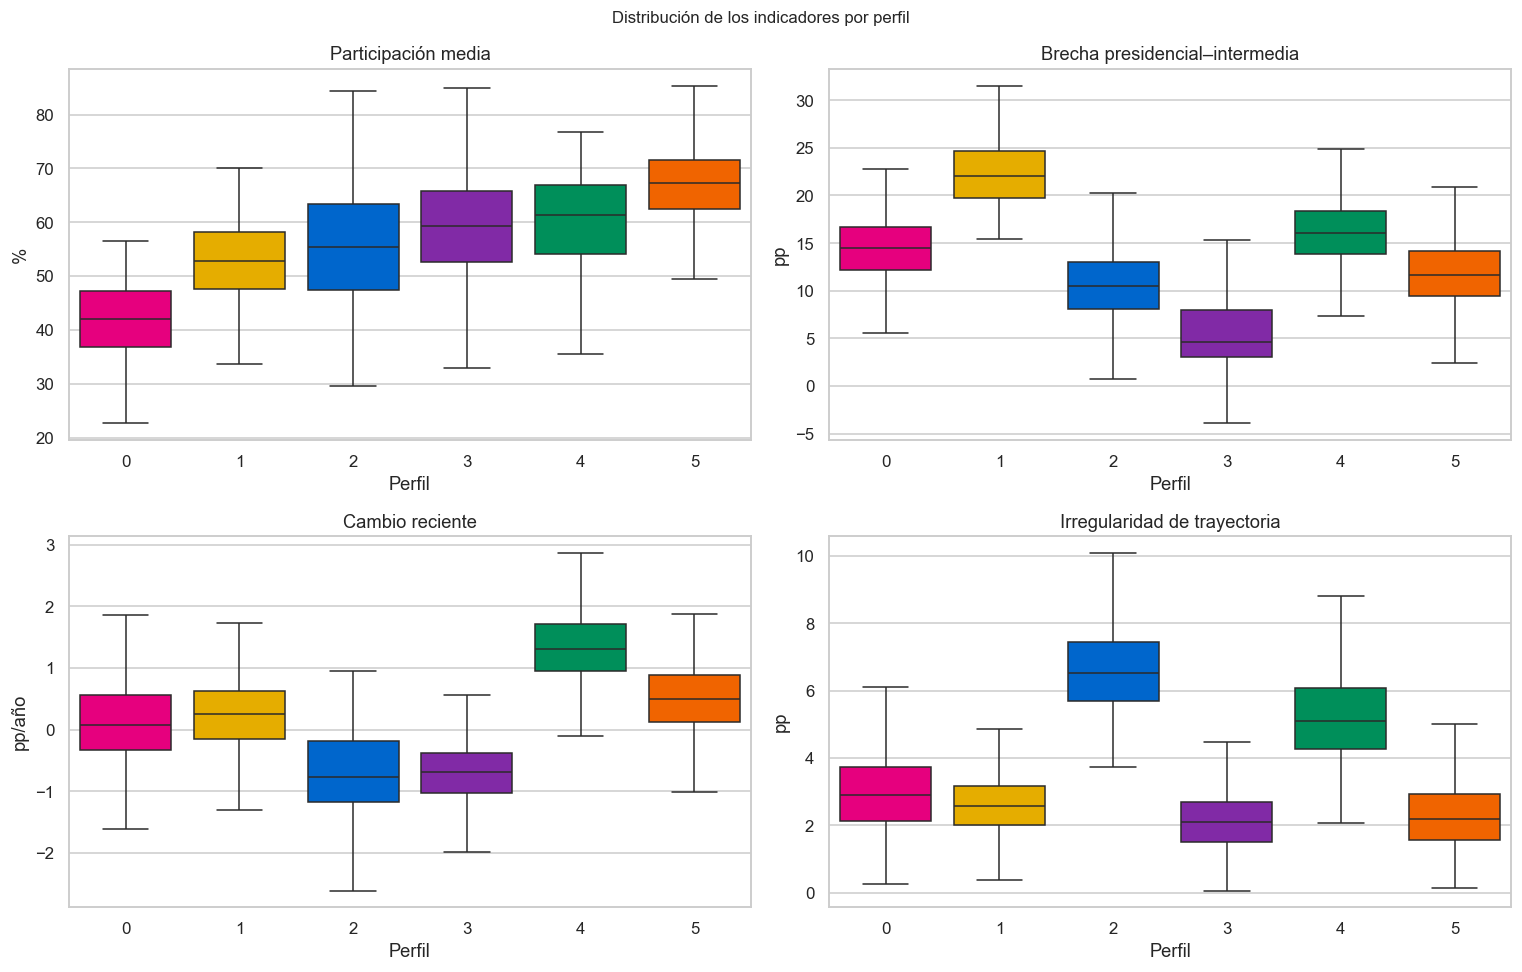

In [10]:
# Las diferencias relativas se expresan en puntos porcentuales, sin multiplicar por 100.
cols_exceso = [f"exceso_{a}" for a in ANIOS]
trayectorias_relativas = U.media_ponderada(u, cols_exceso, PESO_VARIABLES, "cluster").reindex(PERFILES)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for c in PERFILES:
    axes[0].plot(ANIOS, trayectorias.loc[c, COLS_TASA].to_numpy()*100,
                 marker="o", lw=2.3, color=PALETA[c], label=f"Perfil {c}")
    axes[1].plot(ANIOS, trayectorias_relativas.loc[c, cols_exceso].to_numpy(),
                 marker="o", lw=2.3, color=PALETA[c], label=f"Perfil {c}")
axes[0].set(title="Participación observada", ylabel="Participación (%)", xticks=ANIOS)
axes[1].axhline(0, color="black", ls="--", label="Referencia nacional de la misma edad y sexo")
axes[1].set(title="Participación por encima o debajo de lo habitual para su edad y sexo",
            ylabel="Diferencia (puntos porcentuales)", xticks=ANIOS)
for ax in axes:
    ax.set_xlabel("Elección")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(U.ruta_set(U.DIR_FIG, "trayectorias_perfiles.png", FEATURES_SET), dpi=200, bbox_inches="tight"); plt.show(); plt.close()

# Estandarización descriptiva para comparar unidades de medida diferentes en una figura.
media_base = referencia_variables
escala_base = pd.Series({
    v: np.sqrt(np.average((u[v] - media_base[v]) ** 2, weights=u[PESO_VARIABLES]))
    for v in VARIABLES_LONGITUDINALES
}).replace(0, 1)
variables_z = (res[VARIABLES_LONGITUDINALES] - media_base) / escala_base
# Color: contraste estandarizado. Números: magnitudes reales para facilitar la lectura.
columnas = VARIABLES_MODELO_CONTINUAS
etiquetas = ["Participación media (%)", "Brecha electoral (pp)", "Cambio reciente (pp/año)", "Irregularidad (pp)"]
anotaciones = res[columnas].apply(lambda col: col.map(lambda valor: f"{valor:.2f}"))
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(variables_z[columnas], annot=anotaciones, fmt="", cmap=CMAP_CONTRASTE, center=0,
            xticklabels=etiquetas, cbar_kws={"label": "Diferencia respecto al promedio (DE)"}, ax=ax)
ax.set(title="Indicadores de los seis perfiles: valores observados", ylabel="Perfil", xlabel="")
plt.xticks(rotation=15, ha="right")
plt.tight_layout(); plt.savefig(U.ruta_set(U.DIR_FIG, "variables_longitudinales_perfiles.png", FEATURES_SET), dpi=200, bbox_inches="tight"); plt.show(); plt.close()

# Distribución de los indicadores dentro de cada perfil.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, v in zip(axes.ravel(), VARIABLES_MODELO_CONTINUAS):
    sns.boxplot(data=u, x="cluster", y=v, hue="cluster", palette=PALETA, dodge=False, legend=False, saturation=1, showfliers=False, ax=ax)
    ax.set(title=ETIQUETAS_VARIABLES[v], xlabel="Perfil", ylabel=UNIDADES_VARIABLES[v])
fig.suptitle("Distribución de los indicadores por perfil", fontsize=11)
plt.tight_layout(); plt.savefig(U.ruta_set(U.DIR_FIG, "dispersion_participacion.png", FEATURES_SET), dpi=180, bbox_inches="tight"); plt.show(); plt.close()


In [11]:
# Contraste entre cada perfil y su vecino más cercano.
var_interna = pd.DataFrame({c: {
    v: np.average((u.loc[u.cluster.eq(c), v]-res.loc[c,v])**2,
                  weights=u.loc[u.cluster.eq(c), PESO_VARIABLES])
    for v in VARIABLES_MODELO_CONTINUAS} for c in PERFILES}).T
contrastes = []
for c in PERFILES:
    otros = [d for d in PERFILES if d != c]
    vecino = min(otros, key=lambda d: np.linalg.norm(
        variables_z.loc[c, VARIABLES_MODELO_CONTINUAS]-variables_z.loc[d, VARIABLES_MODELO_CONTINUAS]))
    diferencias = res.loc[c, VARIABLES_MODELO_CONTINUAS]-res.loc[vecino, VARIABLES_MODELO_CONTINUAS]
    dispersion = np.sqrt((var_interna.loc[c]+var_interna.loc[vecino])/2).replace(0, np.nan)
    efecto = diferencias.abs()/dispersion
    variable = efecto.idxmax()
    contrastes.append({"cluster": c, "perfil_mas_cercano": vecino,
        "variable_mayor_diferencia": ETIQUETAS_VARIABLES[variable],
        "valor_perfil": res.loc[c,variable], "valor_vecino": res.loc[vecino,variable],
        "diferencia": diferencias[variable], "unidad": UNIDADES_VARIABLES[variable],
        "diferencia_en_sd_interna": efecto[variable]})
contraste_perfiles = pd.DataFrame(contrastes).set_index("cluster")
print("Comparación numérica con el centro de perfil más cercano:")
display(contraste_perfiles.round(2))


Comparación numérica con el centro de perfil más cercano:


,perfil_mas_cercano,variable_mayor_diferencia,valor_perfil,valor_vecino,diferencia,unidad,diferencia_en_sd_interna
cluster,,,,,,,
0,1,Brecha presidencial–intermedia,14.570,22.470,-7.900,pp,2.350
1,0,Brecha presidencial–intermedia,22.470,14.570,7.900,pp,2.350
2,0,Irregularidad de trayectoria,6.720,3.000,3.720,pp,2.920
3,5,Cambio reciente,-0.730,0.470,-1.200,pp/año,2.390
4,5,Irregularidad de trayectoria,5.310,2.320,2.980,pp,2.600
5,3,Cambio reciente,0.470,-0.730,1.200,pp/año,2.390


La comparación con el perfil más cercano identifica los mayores contrastes entre sus centros.
Las diferencias se presentan en unidades originales y respecto a su dispersión interna.

In [12]:
resumen = res.copy()
resumen.insert(0, "perfil", [f"Perfil {c}" for c in resumen.index])
resumen["variables_clustering"] = ";".join(VARIABLES_CLUSTERING)
resumen["variables_diagnostico"] = ";".join(VARIABLES_DIAGNOSTICO)
resumen["peso_resumen_variables"] = PESO_VARIABLES
resumen["candidato_modelo"] = CANDIDATO
resumen["algoritmo_clustering"] = ALGORITMO
resumen["version_modelo"] = u.version_modelo.iloc[0]
resumen["criterio_seleccion"] = CRITERIO
resumen.to_csv(U.ruta_set(U.DIR_TAB, "perfil_resumen.csv", FEATURES_SET))
variables_largo = res[VARIABLES_LONGITUDINALES].reset_index().melt(id_vars="cluster", var_name="variable", value_name="valor")
variables_largo["uso"] = np.where(variables_largo.variable.isin(VARIABLES_CLUSTERING), "clustering", "diagnostico")
variables_largo["unidad"] = variables_largo.variable.map(UNIDADES_VARIABLES)
variables_largo["etiqueta"] = variables_largo.variable.map(ETIQUETAS_VARIABLES)
variables_largo.to_csv(U.ruta_set(U.DIR_TAB, "perfil_variables_longitudinales.csv", FEATURES_SET), index=False)
for numero_variable, (v, (pct, indice)) in enumerate(comp.items(), start=1):
    print(f"[04] Exportando composición {numero_variable}/{len(comp)}: {v}", flush=True)
    pct.to_csv(U.ruta_set(U.DIR_TAB, f"composicion_{v}_pct.csv", FEATURES_SET))
    indice.to_csv(U.ruta_set(U.DIR_TAB, f"composicion_{v}_indice.csv", FEATURES_SET))
dist_edad.to_csv(U.ruta_set(U.DIR_TAB, "distribucion_edad_por_perfil.csv", FEATURES_SET))
u.assign(perfil="Perfil " + u.cluster.astype(str)).to_csv(U.ruta_set(U.DIR_PROC, "segmentos_con_perfil.csv", FEATURES_SET), index=False)
print("Tablas y asignaciones guardadas.")
trayectorias_estandarizadas.to_csv(U.ruta_set(U.DIR_TAB, "trayectorias_estandarizadas.csv", FEATURES_SET))
trayectorias_soporte_comun.to_csv(U.ruta_set(U.DIR_TAB, "trayectorias_soporte_comun.csv", FEATURES_SET))
cobertura_edades.to_csv(U.ruta_set(U.DIR_TAB, "cobertura_estandarizacion.csv", FEATURES_SET),index=False)
comparacion_brechas.to_csv(U.ruta_set(U.DIR_TAB, "brechas_crudas_estandarizadas.csv", FEATURES_SET),index=False)
diferencias_indices.to_csv(U.ruta_set(U.DIR_TAB, "diferencias_composicion.csv", FEATURES_SET),index=False)
dist_edad_segmentos.to_csv(U.ruta_set(U.DIR_TAB, "distribucion_edad_segmentos.csv", FEATURES_SET))
matriz_perfil_ciclo.to_csv(U.ruta_set(U.DIR_TAB, "matriz_perfil_ciclo.csv", FEATURES_SET),index=False)
for v,(pct,indice) in comp_segmentos.items():
    pct.to_csv(U.ruta_set(U.DIR_TAB, f"composicion_{v}_segmentos_pct.csv", FEATURES_SET))
    indice.to_csv(U.ruta_set(U.DIR_TAB, f"composicion_{v}_segmentos_indice.csv", FEATURES_SET))
presencia_entidad.set_index("entidad_fuente").to_csv(U.ruta_set(U.DIR_TAB, "presencia_perfil_entidad.csv", FEATURES_SET))

presencia_distrito.to_csv(U.ruta_set(U.DIR_TAB, "presencia_perfil_distrito.csv", FEATURES_SET))

contraste_perfiles.to_csv(U.ruta_set(U.DIR_TAB, "contraste_perfiles.csv", FEATURES_SET))


[04] Exportando composición 1/4: ciclo_vida
[04] Exportando composición 2/4: sexo
[04] Exportando composición 3/4: region
[04] Exportando composición 4/4: entidad
Tablas y asignaciones guardadas.


## 3. Fichas técnicas
Cada ficha reúne trayectoria, indicadores, mapa y composición por edad, sexo y región, en dos columnas.
Las escalas comunes permiten comparar los perfiles. Las cifras describen segmentos agregados.

[04] Generando y guardando las fichas de los perfiles.
[04] Ficha 1/6: perfil 0
[04] Ficha 2/6: perfil 1
[04] Ficha 3/6: perfil 2
[04] Ficha 4/6: perfil 3
[04] Ficha 5/6: perfil 4
[04] Ficha 6/6: perfil 5
[04] Fichas generadas: 6/6.


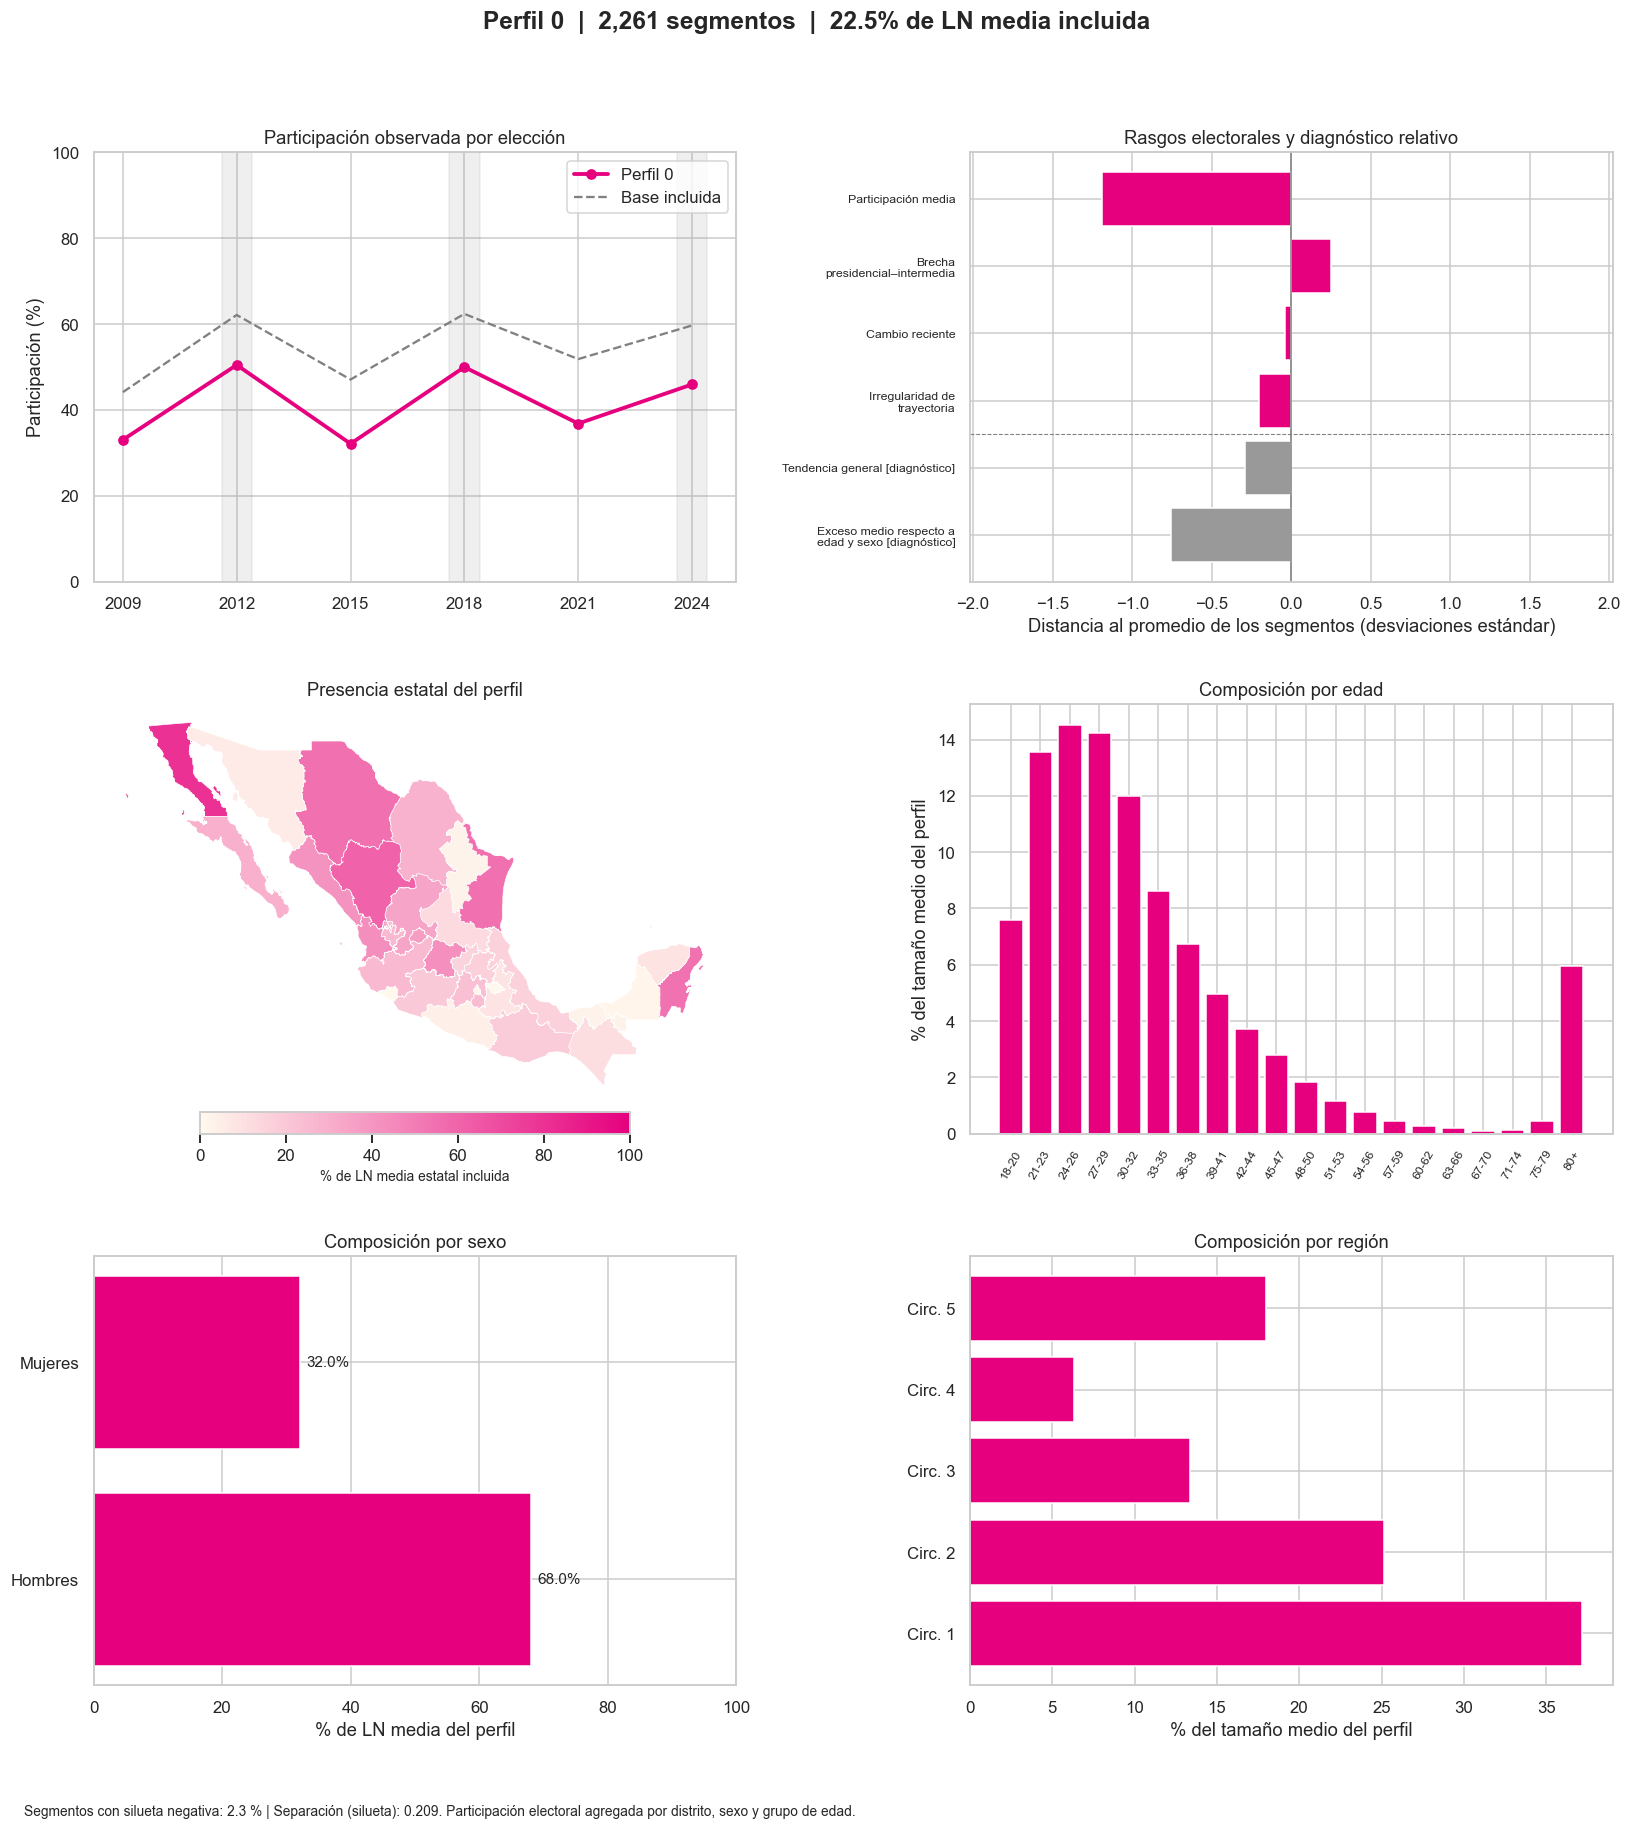

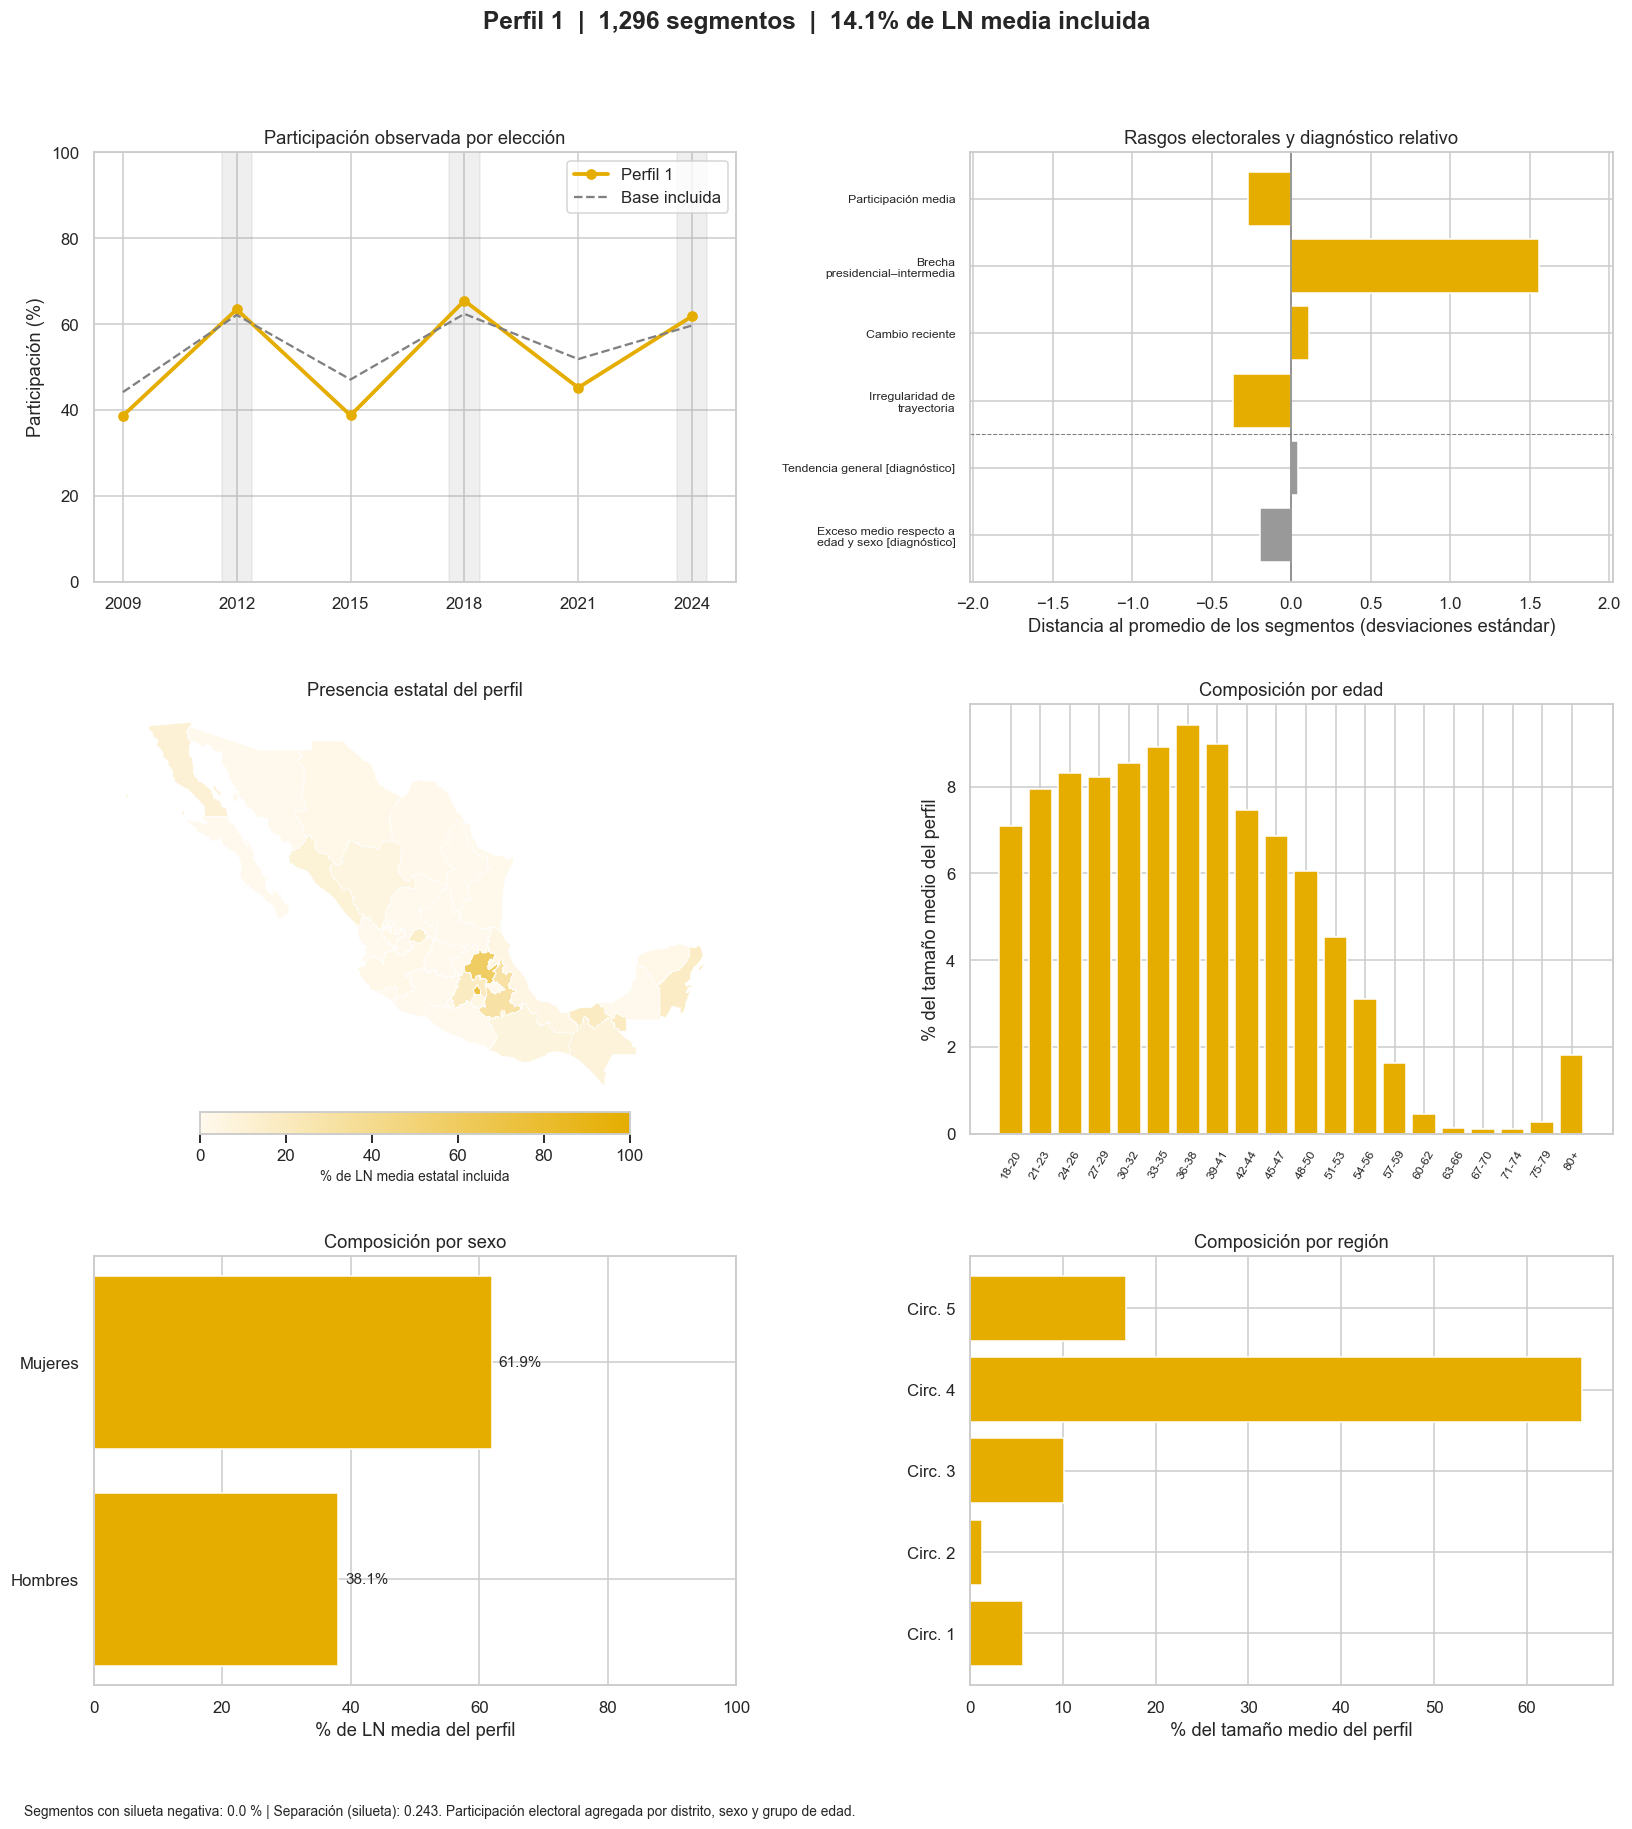

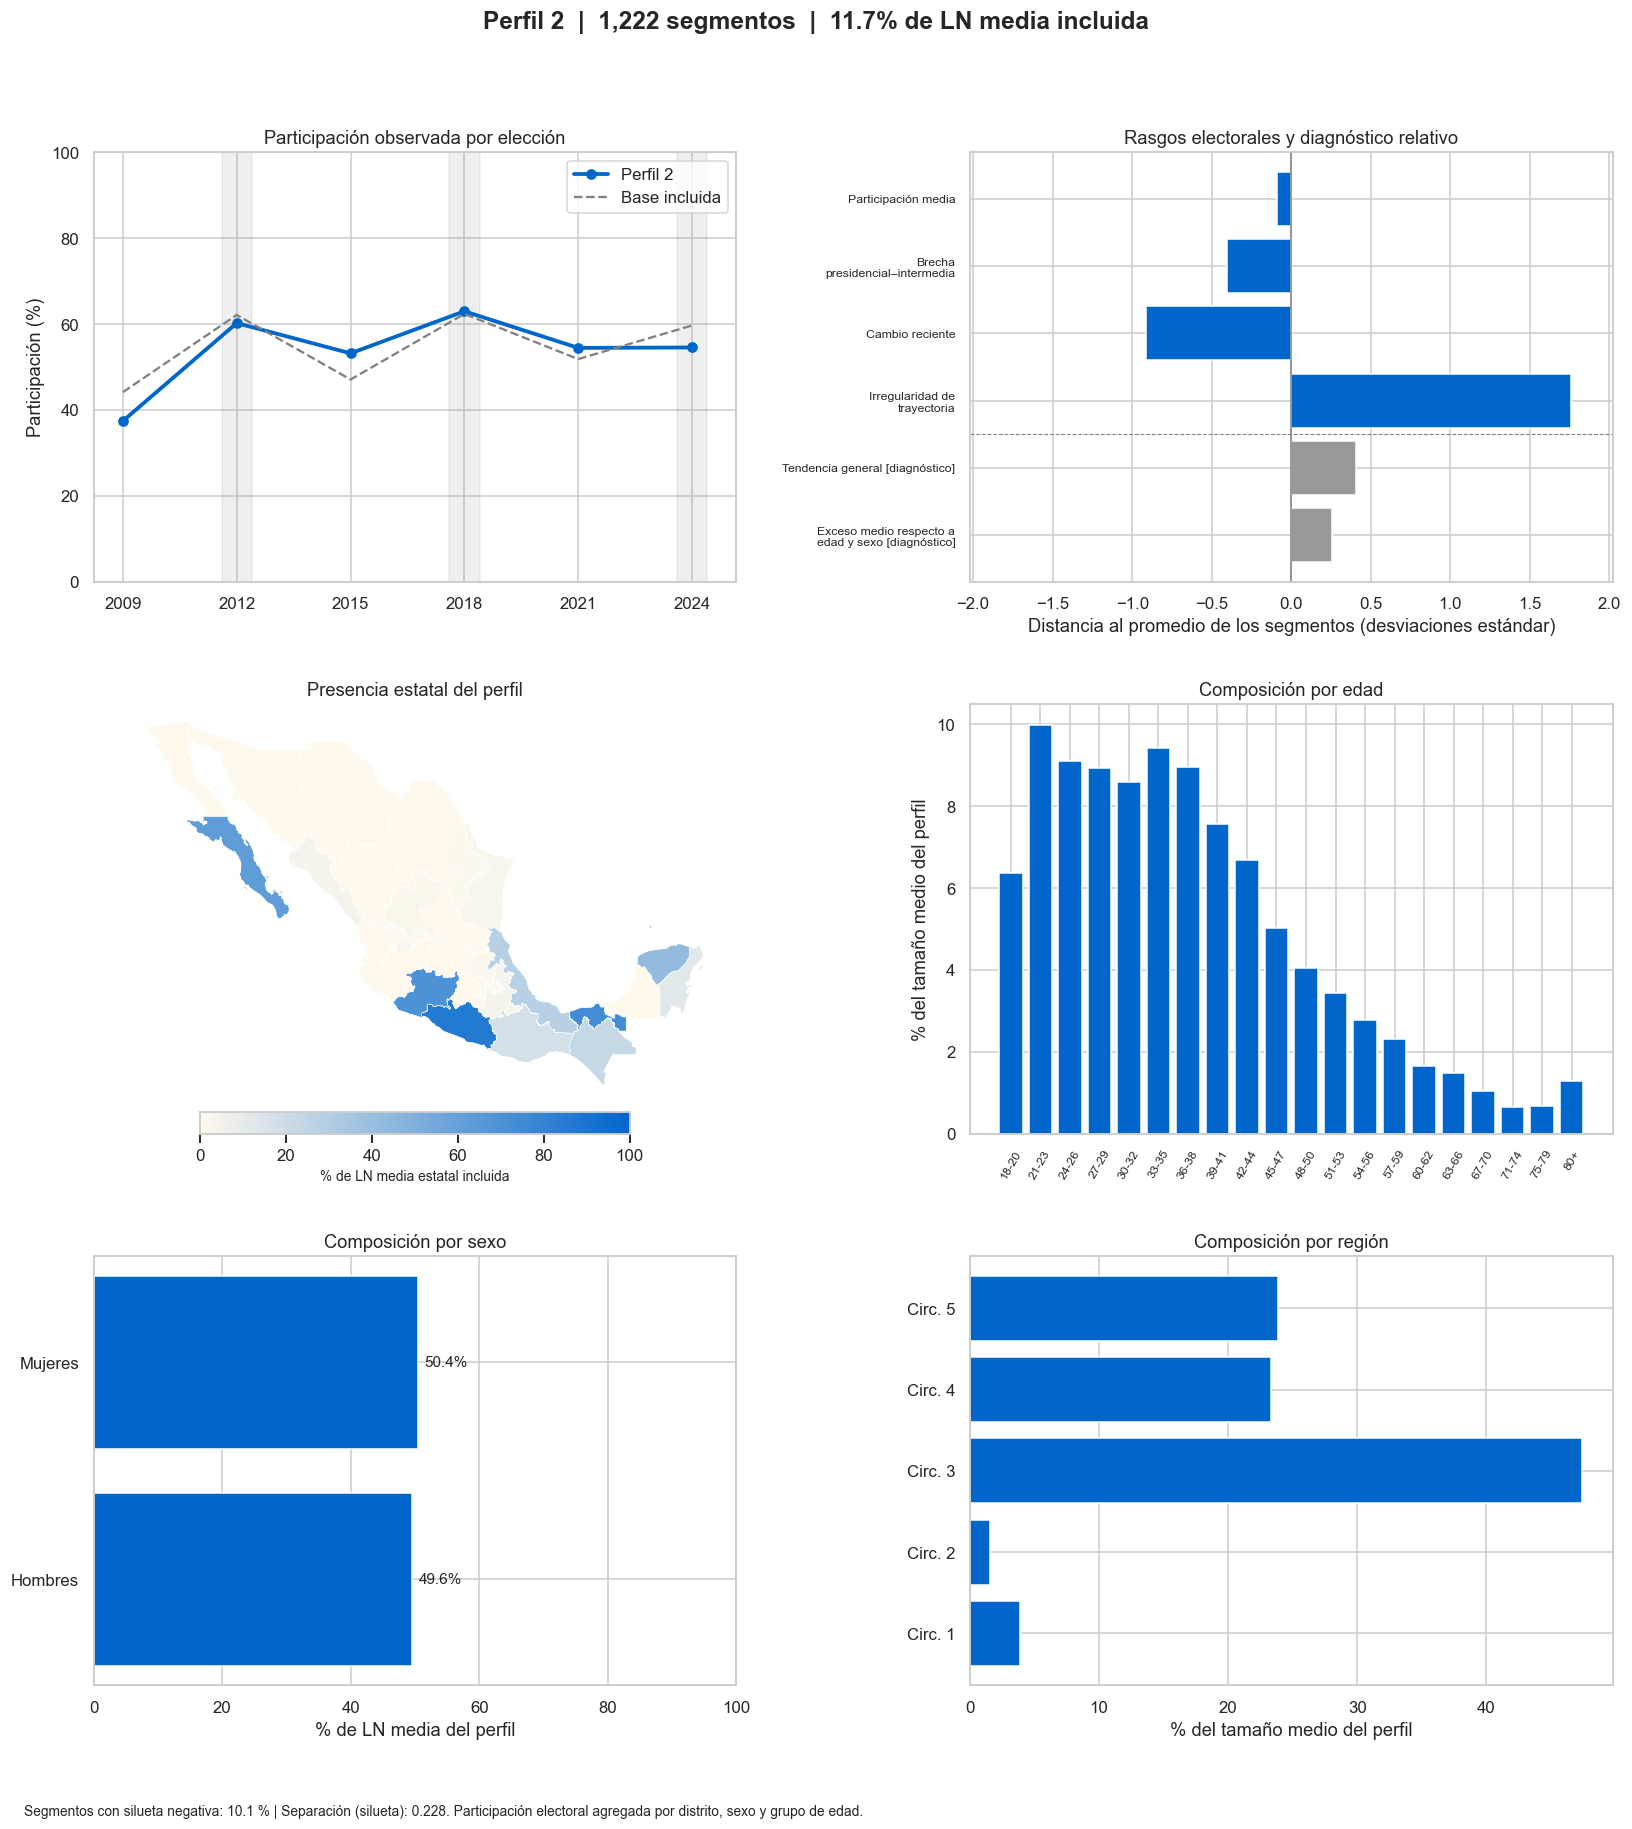

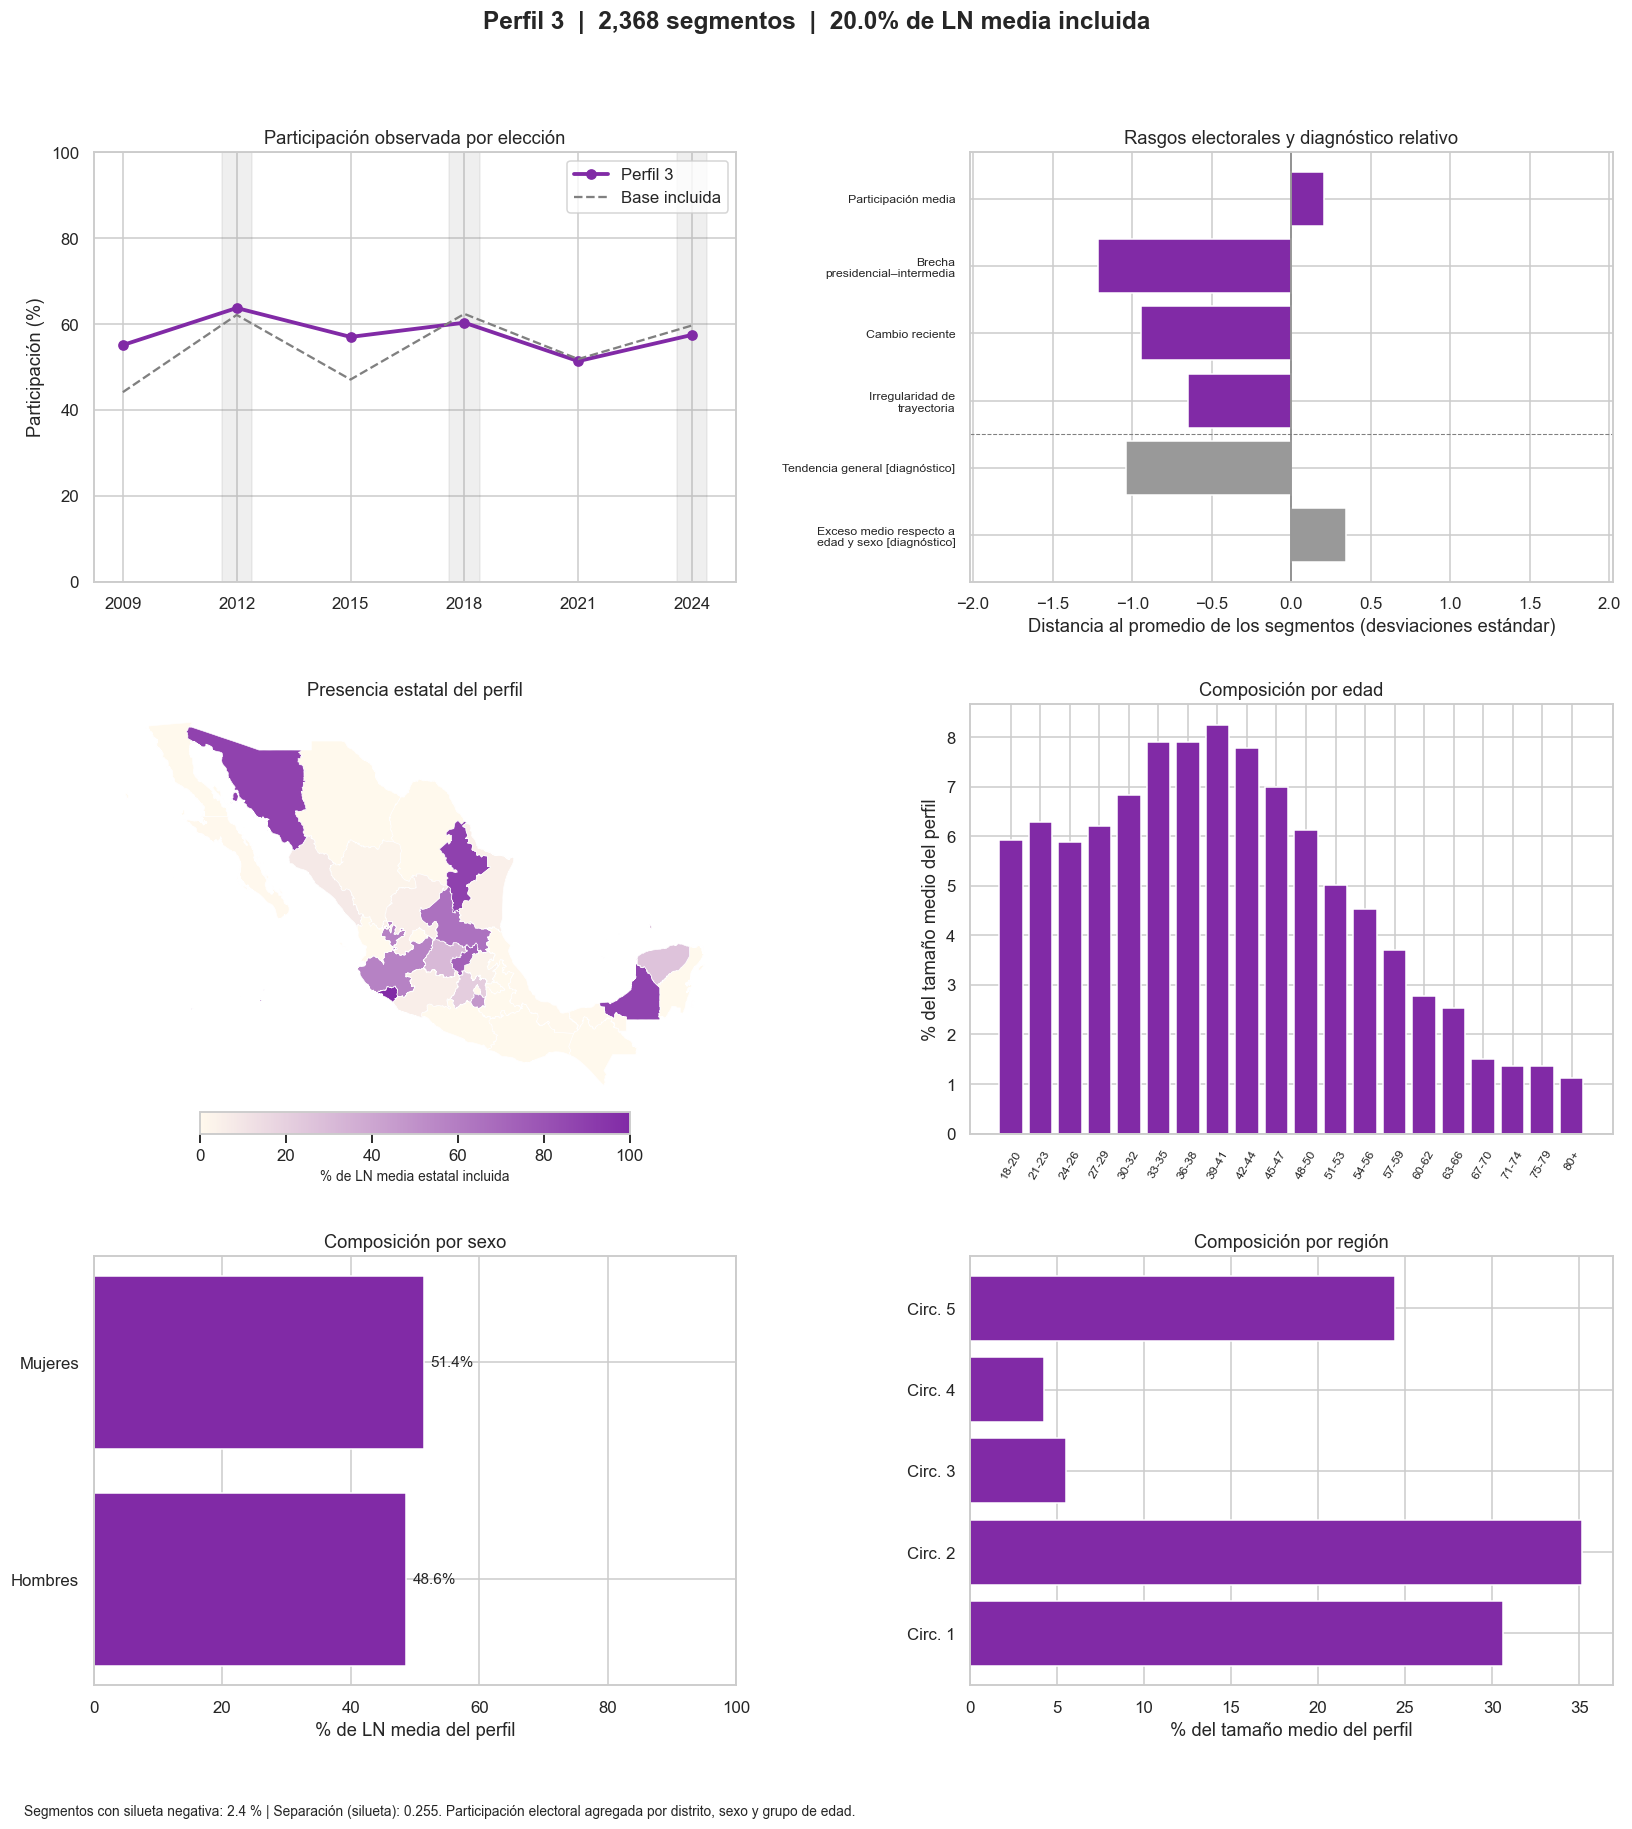

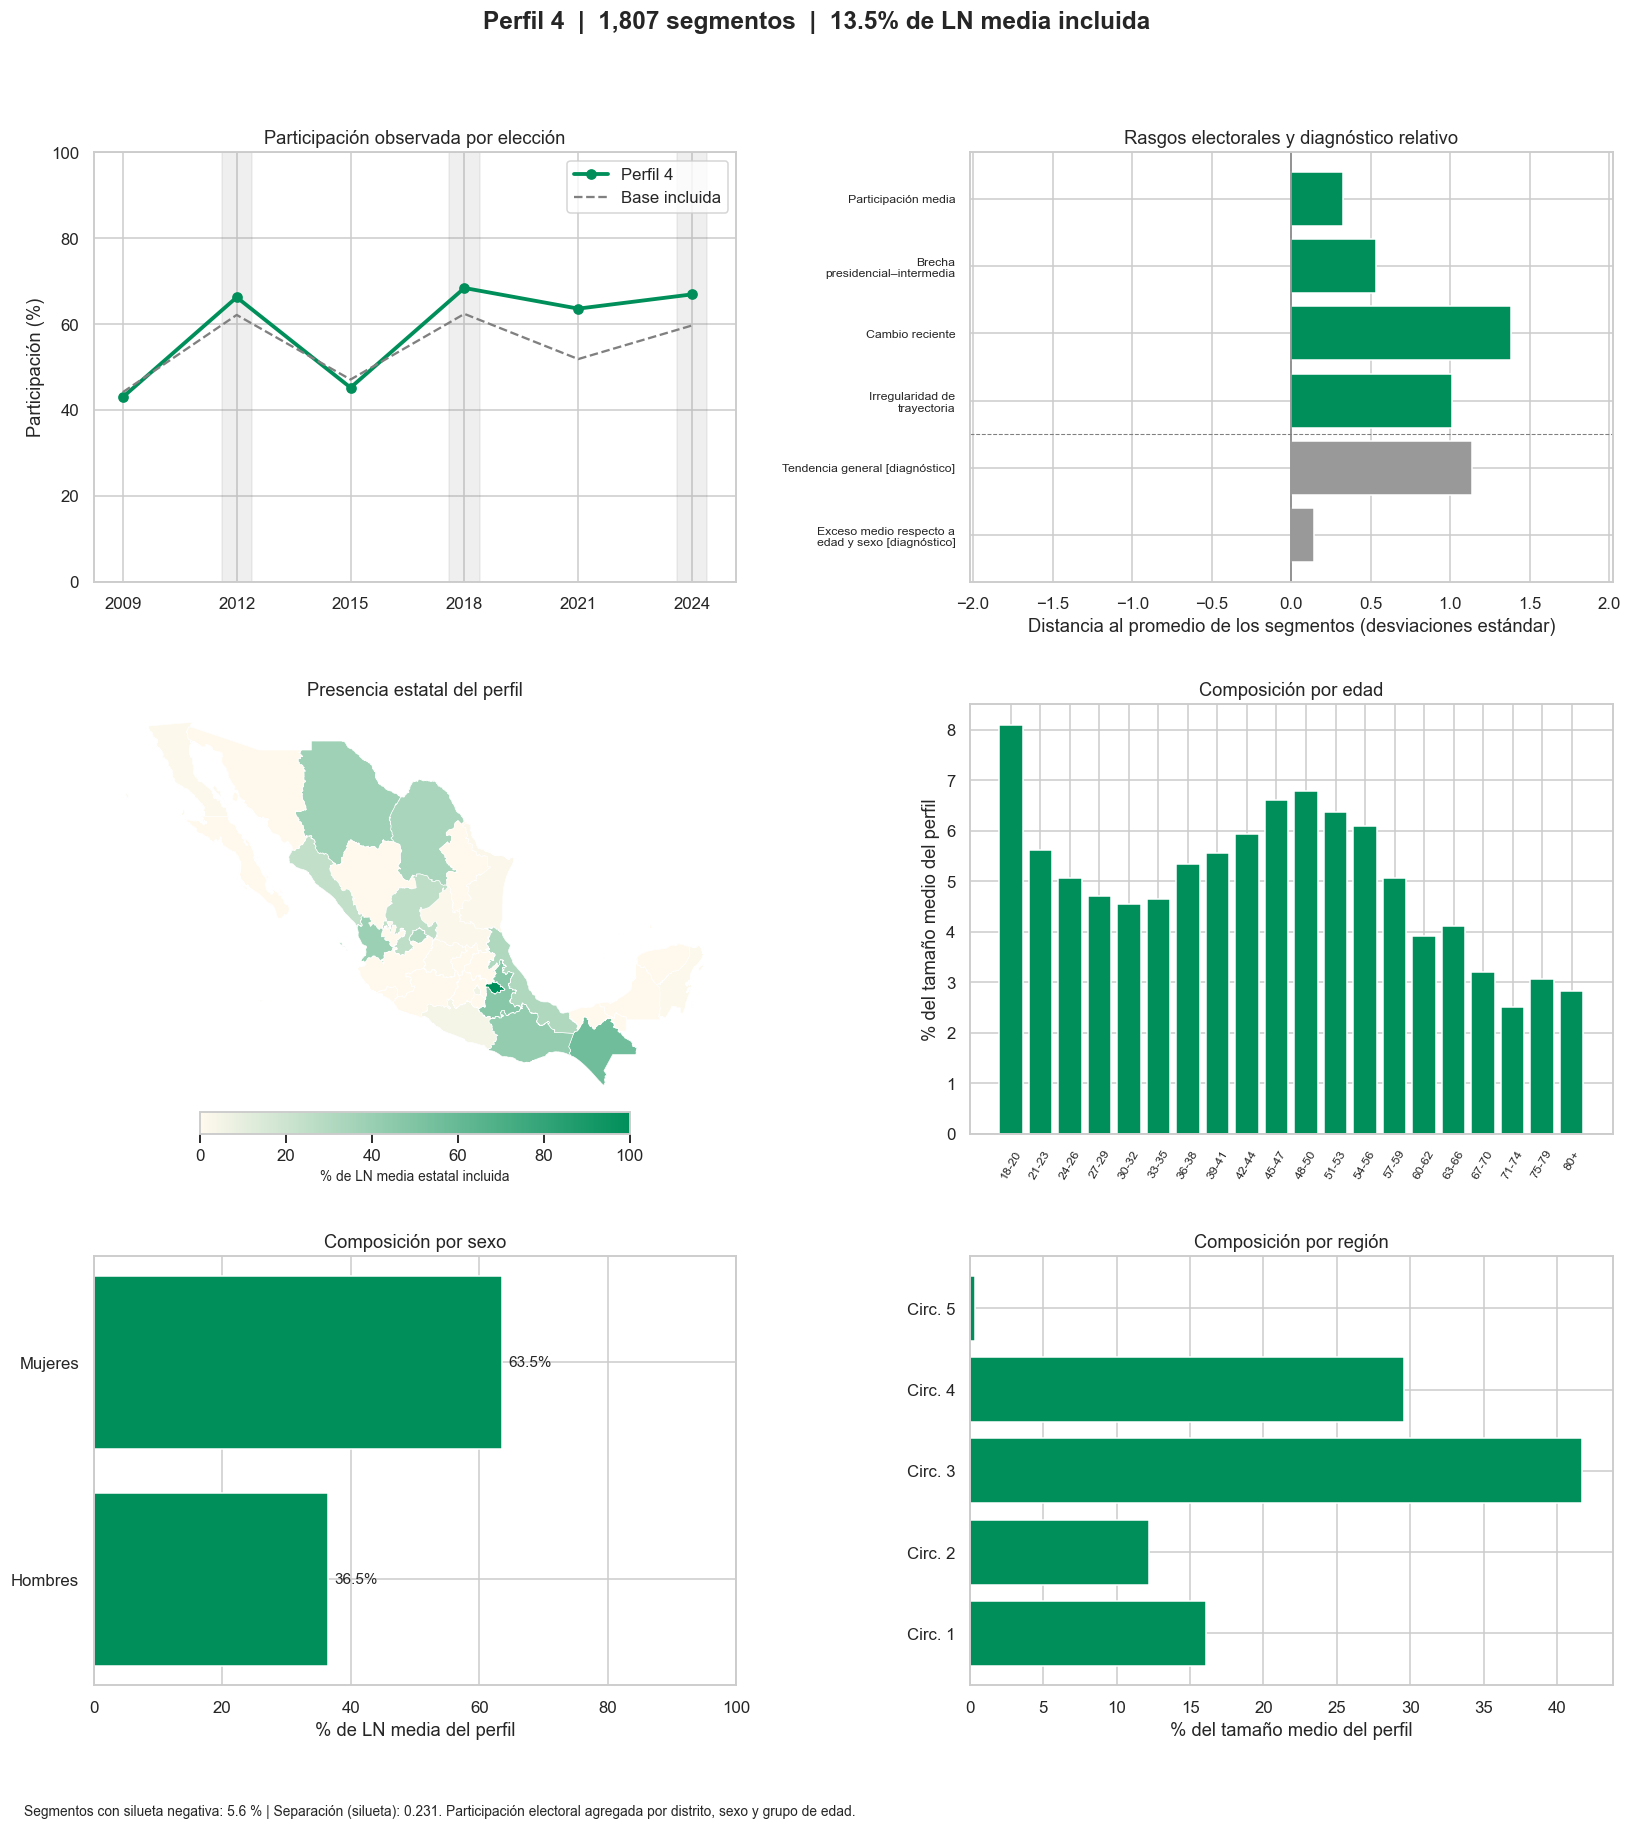

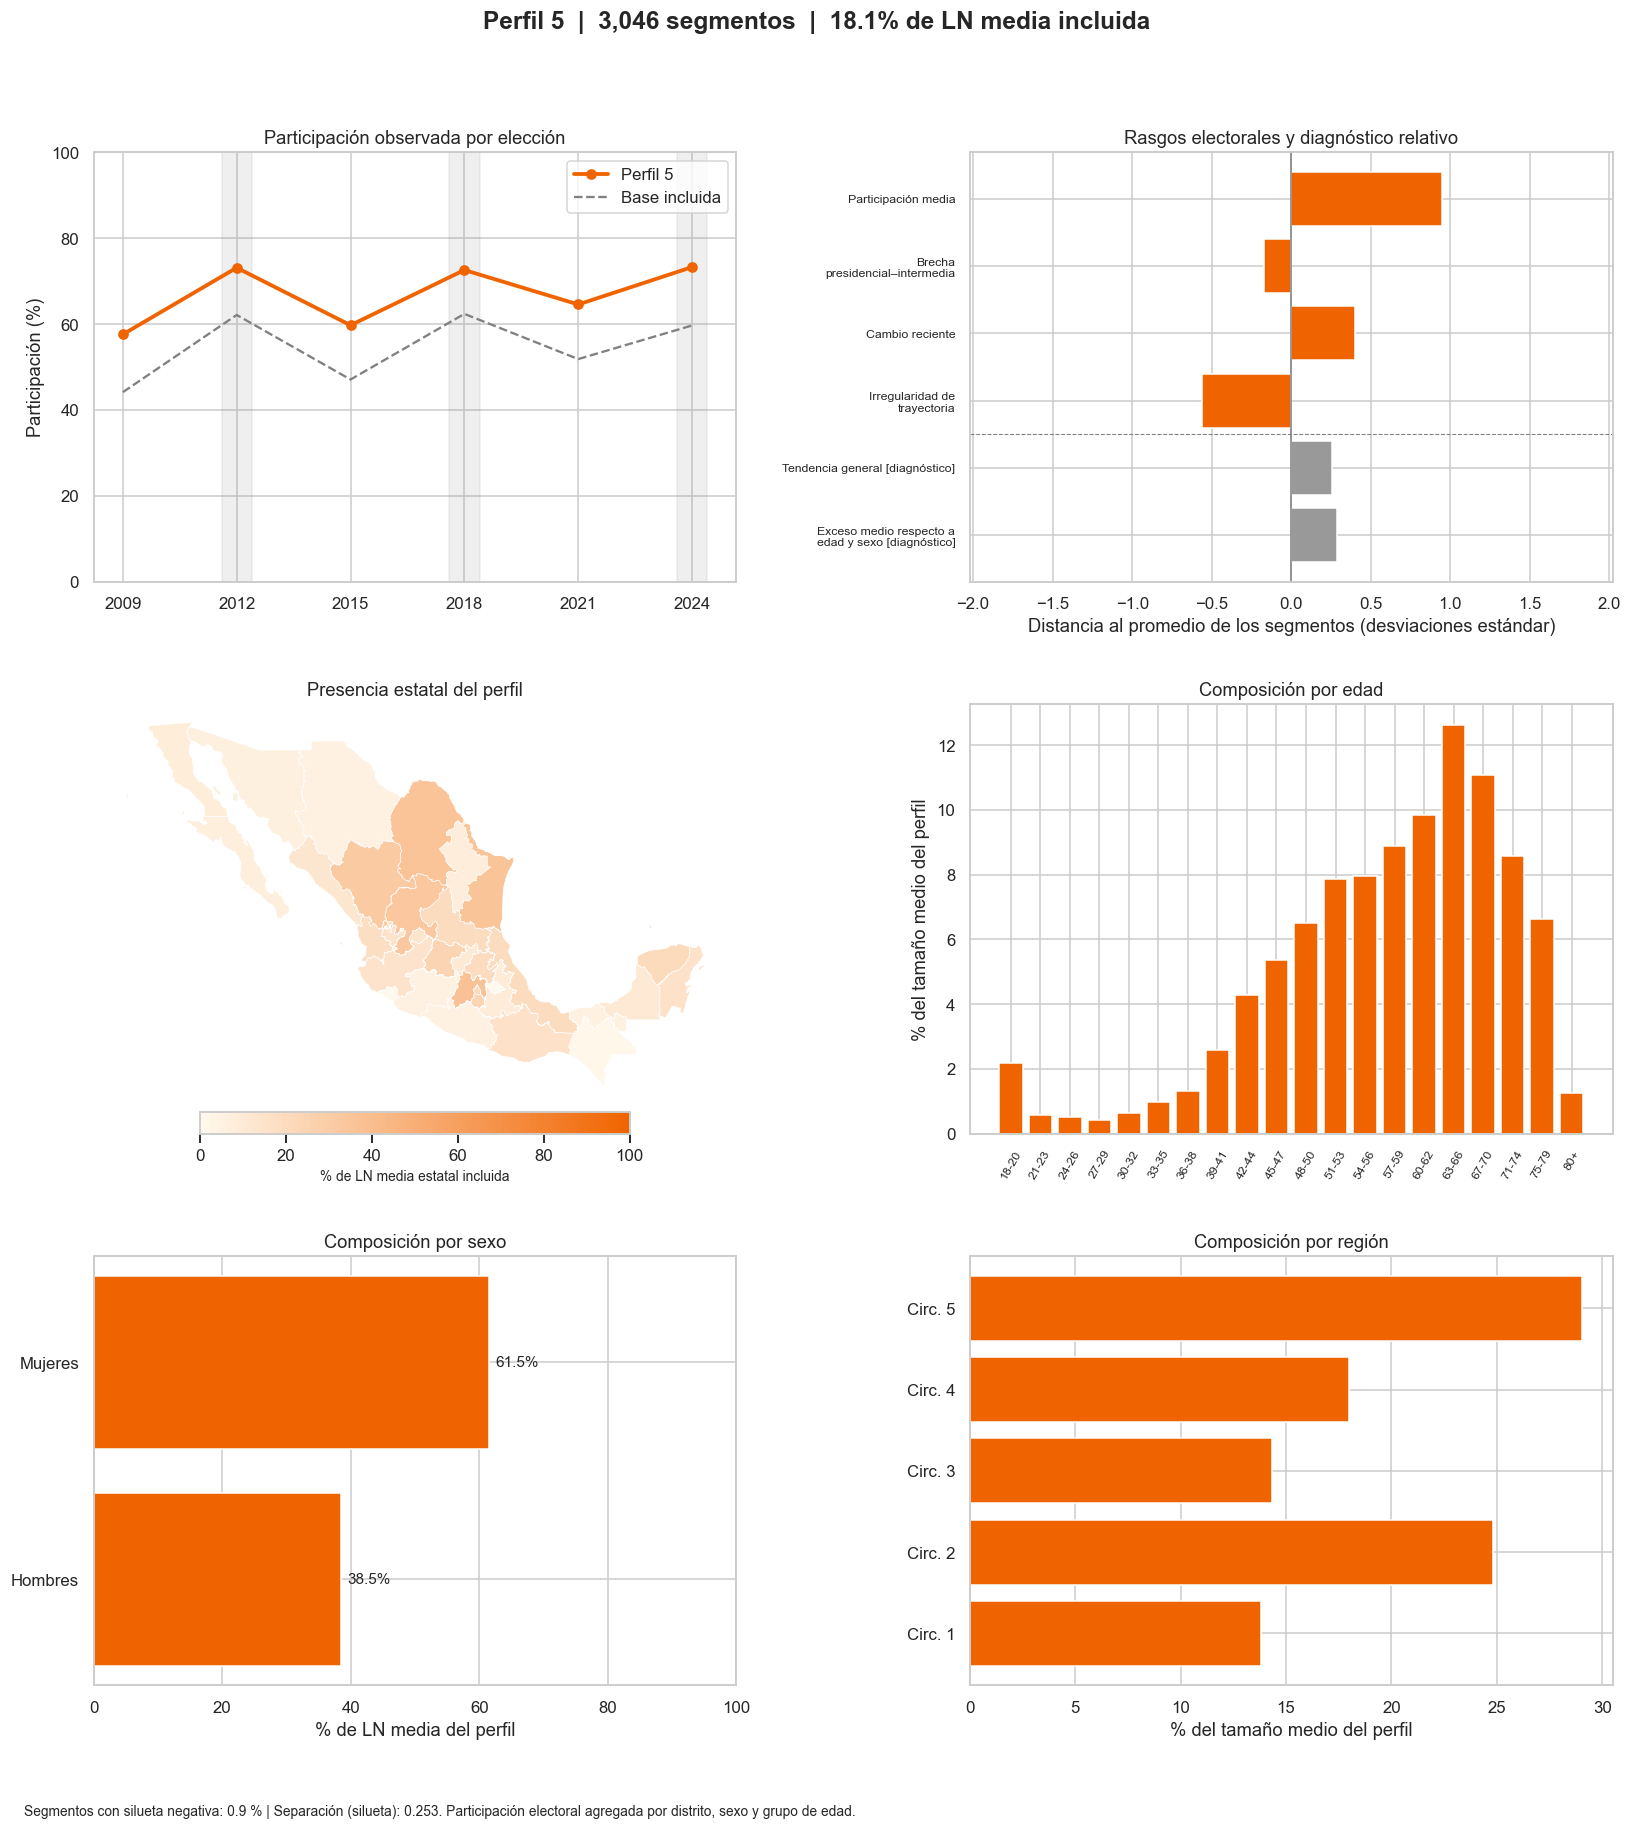

In [13]:
print('[04] Generando y guardando las fichas de los perfiles.', flush=True)
def ficha(c):
    fig, axes = plt.subplots(3, 2, figsize=(15, 17))
    ax1, ax2, ax_mapa, ax3, ax_sexo, ax4 = axes.ravel()
    ax1.plot(ANIOS, trayectorias.loc[c, COLS_TASA].to_numpy()*100,
             "o-", lw=2.5, color=PALETA[c], label=f"Perfil {c}")
    ax1.plot(ANIOS, trayectoria_base.to_numpy()*100, "--", color="gray", label="Base incluida")
    ax1.set_ylim(0, 100)
    ax1.set(title="Participación observada por elección",
            ylabel="Participación (%)", xticks=ANIOS)
    for a in [2012, 2018, 2024]:
        ax1.axvspan(a-.4, a+.4, color="gray", alpha=.12)
    ax1.legend()
    etiquetas = [fill(ETIQUETAS_VARIABLES[v], 26) + (" [diagnóstico]" if v in VARIABLES_DIAGNOSTICO else "") for v in VARIABLES_LONGITUDINALES]
    ax2.barh(etiquetas, variables_z.loc[c, VARIABLES_LONGITUDINALES].to_numpy(), color=[PALETA[c] if v in VARIABLES_MODELO_CONTINUAS else "#999999" for v in VARIABLES_LONGITUDINALES])
    if VARIABLES_DIAGNOSTICO: ax2.axhline(len(VARIABLES_MODELO_CONTINUAS) - .5, color="gray", ls="--", lw=.7)
    ax2.axvline(0, color="gray", lw=1)
    ax2.invert_yaxis()
    limite = max(1., float(variables_z[VARIABLES_LONGITUDINALES].abs().to_numpy().max())*1.15)
    ax2.set_xlim(-limite, limite)
    ax2.set(title="Rasgos electorales y diagnóstico relativo", xlabel="Distancia al promedio de los segmentos (desviaciones estándar)")
    ax2.tick_params(axis="y", labelsize=8)
    pct_edad = t.loc[c] / t.loc[c].sum() * 100
    ax3.bar(np.arange(len(orden_edad)), pct_edad.to_numpy(), color=PALETA[c])
    ax3.set_xticks(np.arange(len(orden_edad)))
    ax3.set_xticklabels(orden_edad, rotation=60, fontsize=8)
    ax3.set(title="Composición por edad", ylabel="% del tamaño medio del perfil")
    pct_region = comp["region"][0].loc[c]
    ax4.barh(pct_region.index, pct_region.to_numpy(), color=PALETA[c])
    ax4.set(title="Composición por región", xlabel="% del tamaño medio del perfil")
    sexo = comp["sexo"][0].loc[c]
    ax_sexo.barh(sexo.index, sexo.to_numpy(), color=PALETA[c])
    for posicion, valor in enumerate(sexo):
        ax_sexo.text(min(valor+1, 95), posicion, f"{valor:.1f}%", va="center", fontsize=10)
    ax_sexo.set(title="Composición por sexo", xlabel="% de LN media del perfil", xlim=(0, 100))
    cmap = mcolors.LinearSegmentedColormap.from_list(f"ficha_{c}", ["#FFF9ED", PALETA[c]])
    mapa_perfiles.plot(column=f"presencia_perfil_{c}", cmap=cmap, vmin=0, vmax=vmax_mapa,
        edgecolor="white", linewidth=.4, ax=ax_mapa,
        missing_kwds={"color": "#E6E6E6", "hatch": "///"})
    ax_mapa.set_title("Presencia estatal del perfil")
    ax_mapa.axis("off")
    sm = plt.cm.ScalarMappable(norm=plt.Normalize(0, vmax_mapa), cmap=cmap)
    sm.set_array([])
    barra = fig.colorbar(sm, ax=ax_mapa, orientation="horizontal", fraction=.05, pad=.02)
    barra.set_label("% de LN media estatal incluida", fontsize=9)
    fig.suptitle(f"Perfil {c}  |  {int(res.loc[c, 'n_segmentos']):,} segmentos  |  {res.loc[c, '%_ln_media']:.1f}% de LN media incluida", fontsize=16, fontweight="bold")
    fig.text(.02, .015,
        f"Segmentos con silueta negativa: {res.loc[c, 'porcentaje_silueta_negativa']:.1f} % | "
        f"Separación (silueta): {res.loc[c, 'silueta_media']:.3f}. "
        "Participación electoral agregada por distrito, sexo y grupo de edad.", fontsize=9)
    fig.tight_layout(rect=(0, .045, 1, .95), w_pad=2.5, h_pad=2.5)
    fig.savefig(U.ruta_set(U.DIR_FIG, f"ficha_perfil_{c}.png", FEATURES_SET), dpi=200, bbox_inches="tight")
    plt.show(); plt.close()

for numero, c in enumerate(PERFILES, start=1):
    print(f"[04] Ficha {numero}/{len(PERFILES)}: perfil {c}", flush=True)
    ficha(c)
print(f"[04] Fichas generadas: {len(PERFILES)}/{len(PERFILES)}.", flush=True)
